In [1]:
# ============================================================
# 1. MANIPULAÇÃO E ANÁLISE DE DADOS
# ============================================================

import pandas as pd
import numpy as np
import sidetable


# ============================================================
# 2. VISUALIZAÇÃO DE DADOS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


# ============================================================
# 3. TESTES ESTATÍSTICOS
# ============================================================

from scipy.stats import chi2_contingency


# ============================================================
# 4. PREPARAÇÃO E VALIDAÇÃO DOS DADOS
# ============================================================

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# ============================================================
# 5. ALGORITMOS DE MACHINE LEARNING
# ============================================================

# Modelos lineares
from sklearn.linear_model import LogisticRegression

# Modelos baseados em distância
from sklearn.neighbors import KNeighborsClassifier

# Redes neurais
from sklearn.neural_network import MLPClassifier

# Árvores de decisão
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Ensemble Learning
from sklearn.ensemble import RandomForestClassifier

# Gradient Boosting
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


# ============================================================
# 6. MÉTRICAS E AVALIAÇÃO DOS MODELOS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    RocCurveDisplay
)

In [2]:
import os
candidates = ['../06_data/history.csv', '06_data/history.csv', 'history.csv', '../../history.csv']
data_path = next((p for p in candidates if os.path.exists(p)), '06_data/history.csv')
df = pd.read_csv(data_path)
display(df)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 3...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet ...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for o...,3904


In [3]:
# Verificando o formato dos dados
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5634 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   object 
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5634 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,5634,5634,4578-PHJYZ,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,5634,2,Male,2835,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,5634.0,NaN,NaN,NaN,0.164714,0.370955,0.0,0.0,0.0,0.0,1.0
Partner,5634,2,No,2907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,5634,2,No,3949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,5634,74,1,475,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PhoneService,5634,4,Yes,5041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,5634,3,No,2704,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,5634,3,Fiber optic,2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,5634,3,No,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Verificando dados nulos e seu percentual
df.stb.missing()

,missing,total,percent
TotalCharges,278,5634,4.934327
gender,0,5634,0.000000
customerID,0,5634,0.000000
Partner,0,5634,0.000000
Dependents,0,5634,0.000000
tenure,0,5634,0.000000
SeniorCitizen,0,5634,0.000000
PhoneService,0,5634,0.000000
MultipleLines,0,5634,0.000000
OnlineSecurity,0,5634,0.000000


In [6]:
print(df.isna().sum())

customerID            0
gender                0
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity        0
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges        0
TotalCharges        278
Churn                 0
CustomerFeedback      0
MonthlyIncome         0
dtype: int64


In [7]:
# Verificando dados duplicados
df.duplicated().sum()

np.int64(0)

In [8]:
df1 = df.copy()
display(df1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 3...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet ...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for o...,3904


Convertendo tipos e encoding de variáveis

In [9]:
# 1. gender: converte Male para 0 e Female para 1
df1['gender'] = df['gender'].map({'Male': 0, 'Female': 1}).astype('Int64')

# 2. SeniorCitizen: mantém 0 (Não) e 1 (Sim), convertendo para tipo inteiro
df1['SeniorCitizen'] = df1['SeniorCitizen'].astype('Int64')

# 3. Partner: converte No para 0 e Yes para 1
df1['Partner'] = df['Partner'].map({'No': 0, 'Yes': 1}).astype('Int64')

# 4. Dependents: converte No para 0 e Yes para 1
df1['Dependents'] = df['Dependents'].map({'No': 0, 'Yes': 1}).astype('Int64')

# 5. tenure: converte os valores para números inteiros, valores inválidos, como 'unknown', são transformados em NaN, utiliza Int64 (nullable) para permitir valores ausentes
df1['tenure'] = pd.to_numeric(df['tenure'], errors='coerce').astype('Int64')

# 6. PhoneService: remove espaços e normaliza letras maiúsculas/minúsculas, em seguida, converte no para 0 e yes para 1
df1['PhoneService'] = (
    df['PhoneService']
    .str.strip()
    .str.lower()
    .map({'no': 0, 'yes': 1})
    .astype('Int64')
)

# 7. PaperlessBilling: converte No para 0 e Yes para 1
df1['PaperlessBilling'] = df['PaperlessBilling'].map({'No': 0, 'Yes': 1}).astype('Int64')

# 8. Churn: converte No para 0 e Yes para 1, é a variável-alvo (target) do modelo preditivo
df1['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1}).astype('Int64')

# 9. Verificação: exibe os tipos de dados após as transformações
df1.info()

# 10. Verificação: exibe a quantidade de valores ausentes nas colunas tratadas
colunas_tratadas = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'tenure', 'PhoneService', 'PaperlessBilling', 'Churn'
]

print("\nValores ausentes após as transformações:")
print(df1[colunas_tratadas].isna().sum())

# 11. Visualização: exibe as primeiras cinco linhas da base transformada
display(df1.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5634 non-null   Int64  
 2   SeniorCitizen     5634 non-null   Int64  
 3   Partner           5634 non-null   Int64  
 4   Dependents        5634 non-null   Int64  
 5   tenure            5615 non-null   Int64  
 6   PhoneService      5634 non-null   Int64  
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5634 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   Int64  


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,0,0,1,1,52,1,No,DSL,No,...,Yes,No,One year,1,Electronic check,68.75,3482.85,0,I have been a customer with this internet prov...,6532
1,6289-CPNLD,0,0,1,1,33,1,No,DSL,No,...,Yes,Yes,One year,1,Mailed check,73.90,2405.05,1,I've been a customer with this company for ove...,7634
2,2682-KEVRP,1,1,0,0,22,1,No,No,No internet service,...,No internet service,No internet service,One year,1,Mailed check,20.05,417.00,0,I have been a customer with this company for 2...,3628
3,5697-GOMBF,1,1,1,1,28,0,No phone service,DSL,No,...,Yes,No,Month-to-month,1,Electronic check,35.90,973.65,0,I have been a customer with this internet prov...,7851
4,9717-QEBGU,0,0,0,0,2,1,No,Fiber optic,No,...,No,No,Month-to-month,1,Electronic check,70.30,144.00,0,I have been using the fiber optic internet ser...,1691


In [10]:
df1.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,5634,5634,4578-PHJYZ,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,5634.0,<NA>,<NA>,<NA>,0.496805,0.500034,0.0,0.0,0.0,1.0,1.0
SeniorCitizen,5634.0,<NA>,<NA>,<NA>,0.164714,0.370955,0.0,0.0,0.0,0.0,1.0
Partner,5634.0,<NA>,<NA>,<NA>,0.484026,0.499789,0.0,0.0,0.0,1.0,1.0
Dependents,5634.0,<NA>,<NA>,<NA>,0.299077,0.457894,0.0,0.0,0.0,1.0,1.0
tenure,5615.0,<NA>,<NA>,<NA>,32.306144,24.48471,0.0,9.0,29.0,55.0,72.0
PhoneService,5634.0,<NA>,<NA>,<NA>,0.900071,0.299932,0.0,1.0,1.0,1.0,1.0
MultipleLines,5634,3,No,2704,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,5634,3,Fiber optic,2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,5634,3,No,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# 1. PaymentMethod: aplica One-Hot Encoding às 4 categorias de pagamento
# drop_first=False mantém todas as categorias
# dtype='int64' garante que os valores sejam 0 ou 1
payment_dummies = pd.get_dummies(
    df1['PaymentMethod'],
    prefix='PaymentMethod',
    drop_first=False,
    dtype='int64'
)

# 2. Adiciona as 4 novas colunas ao DataFrame
df1 = pd.concat([df1, payment_dummies], axis=1)

# 3. Remove a coluna categórica original
df1 = df1.drop(columns=['PaymentMethod'])

# 4. Verifica as novas colunas criadas
display(payment_dummies.head())

# 5. Confere a estrutura atualizada da base
df1.info()


,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0
1,0,0,0,1
2,0,0,0,1
3,0,0,1,0
4,0,0,1,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 26 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   customerID                               5634 non-null   object 
 1   gender                                   5634 non-null   Int64  
 2   SeniorCitizen                            5634 non-null   Int64  
 3   Partner                                  5634 non-null   Int64  
 4   Dependents                               5634 non-null   Int64  
 5   tenure                                   5615 non-null   Int64  
 6   PhoneService                             5634 non-null   Int64  
 7   MultipleLines                            5634 non-null   object 
 8   InternetService                          5634 non-null   object 
 9   OnlineSecurity                           5634 non-null   object 
 10  OnlineBackup                             5634 no

In [12]:
df1.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,5634,5634,4578-PHJYZ,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,5634.0,<NA>,<NA>,<NA>,0.496805,0.500034,0.0,0.0,0.0,1.0,1.0
SeniorCitizen,5634.0,<NA>,<NA>,<NA>,0.164714,0.370955,0.0,0.0,0.0,0.0,1.0
Partner,5634.0,<NA>,<NA>,<NA>,0.484026,0.499789,0.0,0.0,0.0,1.0,1.0
Dependents,5634.0,<NA>,<NA>,<NA>,0.299077,0.457894,0.0,0.0,0.0,1.0,1.0
tenure,5615.0,<NA>,<NA>,<NA>,32.306144,24.48471,0.0,9.0,29.0,55.0,72.0
PhoneService,5634.0,<NA>,<NA>,<NA>,0.900071,0.299932,0.0,1.0,1.0,1.0,1.0
MultipleLines,5634,3,No,2704,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,5634,3,Fiber optic,2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,5634,3,No,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# Analisando visualmente a distribuição das variáveis e churn
# Remove customerID apenas se a coluna existir
df1 = df1.drop(columns="customerID", errors="ignore")

# Gera os histogramas das variáveis
for coluna in df1.columns:
    grafico = px.histogram(df1, x=coluna, color="Churn")
    grafico.show()

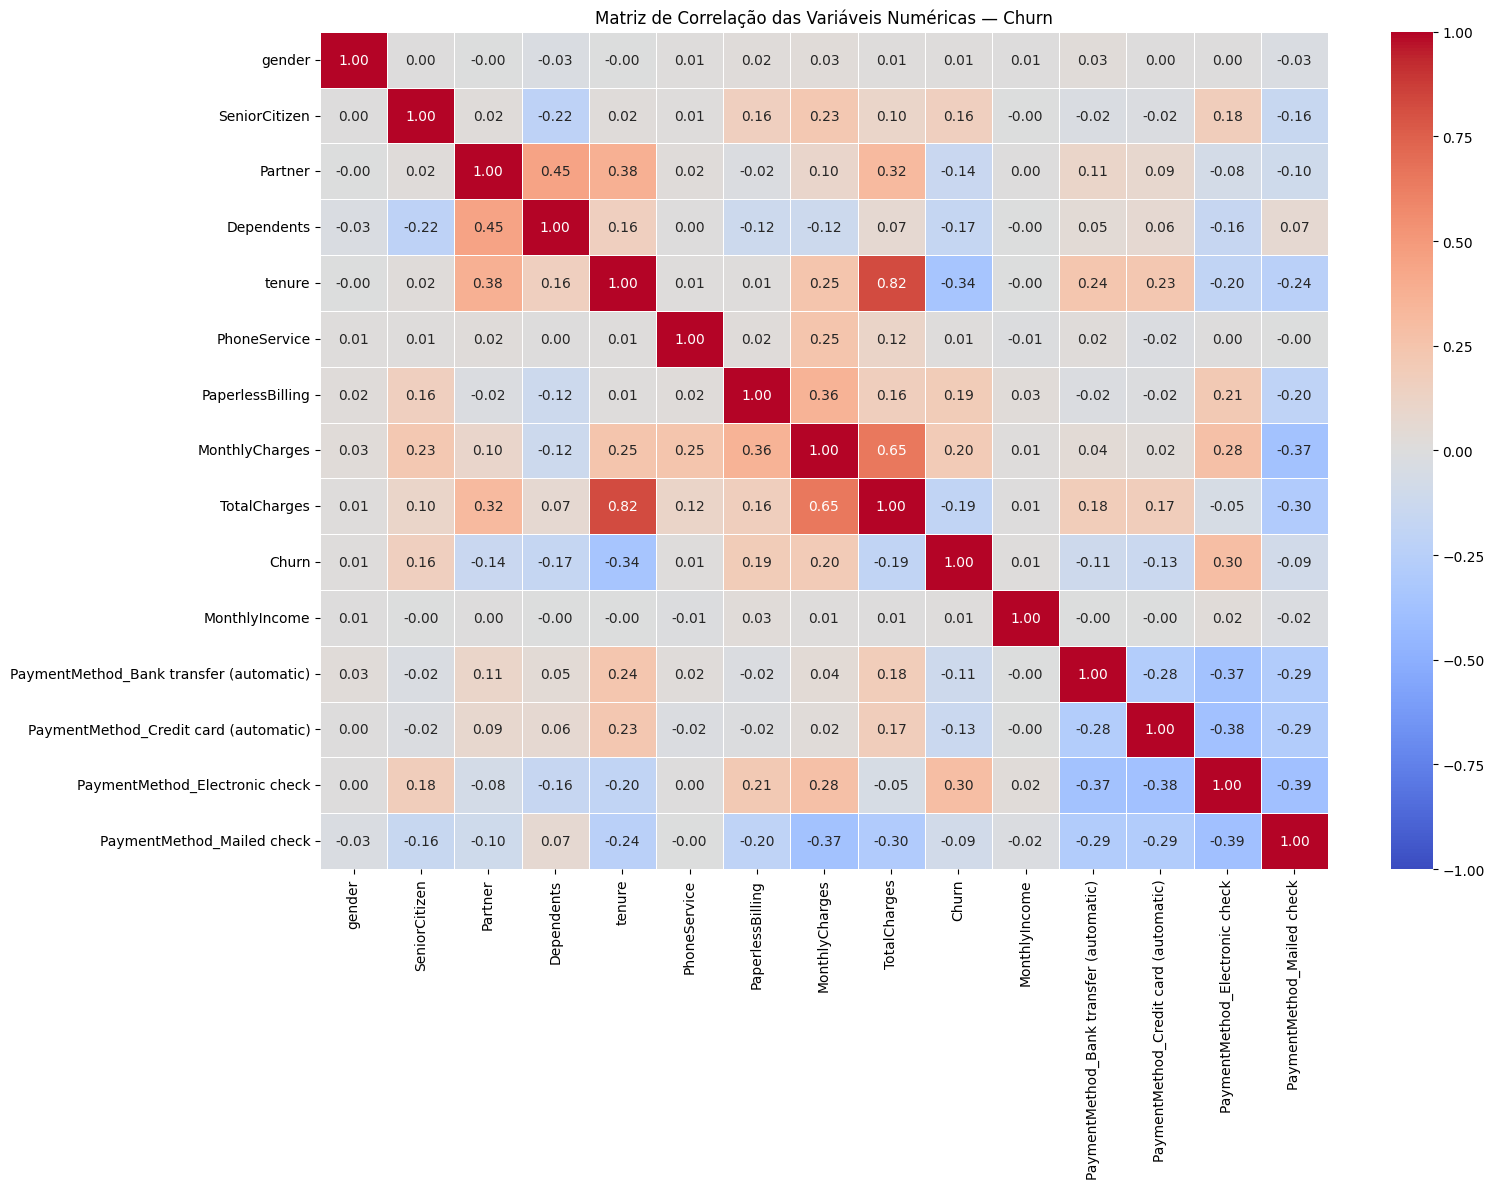

In [14]:
# 1. Seleciona todas as variáveis numéricas do DataFrame df1
# Inclui int64, Int64 e float64, além das variáveis binárias (0/1)
num_cols = df1.select_dtypes(include='number').columns

# 2. Calcula a matriz de correlação de Pearson
# Valores variam de -1 (correlação negativa) a +1 (positiva)
corr = df1[num_cols].corr(method='pearson')

# 3. Define o tamanho do gráfico de acordo com a quantidade de variáveis
plt.figure(figsize=(16, 12))

# 4. Cria o mapa de calor das correlações
sns.heatmap(
    corr,
    annot=True,         # Exibe os coeficientes nas células
    fmt='.2f',          # Exibe duas casas decimais
    cmap='coolwarm',    # Azul = negativa; vermelho = positiva
    vmin=-1,            # Limite inferior da escala
    vmax=1,             # Limite superior da escala
    center=0,           # Centraliza a escala no zero
    linewidths=0.5      # Adiciona linhas entre as células
)

# 5. Configura o título e ajusta o layout
plt.title('Matriz de Correlação das Variáveis Numéricas — Churn')
plt.tight_layout()

# 6. Exibe o gráfico
plt.show()

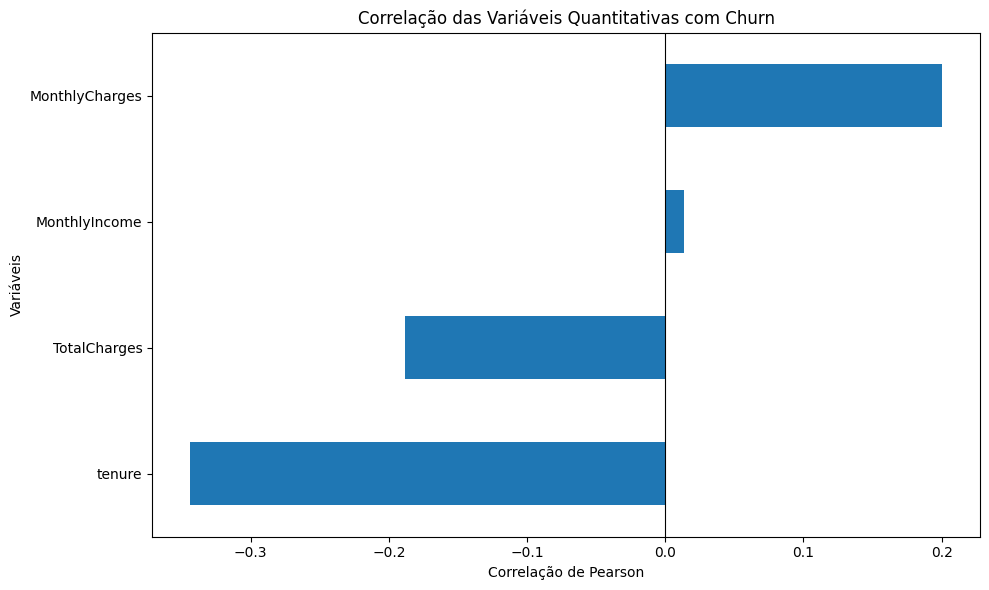

In [15]:
# 1. Define explicitamente as variáveis quantitativas
num_cols = [
    'tenure',
    'MonthlyIncome',
    'MonthlyCharges',
    'TotalCharges'
]

# 2. Calcula a correlação de Pearson com Churn
corr_churn = (
    df1[num_cols + ['Churn']]
    .corr(method='pearson')['Churn']
    .drop('Churn')
    .sort_values()
)

# 3. Define o tamanho do gráfico
plt.figure(figsize=(10, 6))

# 4. Cria o gráfico de barras horizontais
corr_churn.plot(kind='barh')

# 5. Adiciona uma linha de referência para correlação zero
plt.axvline(x=0, color='black', linewidth=0.8)

# 6. Configura título e eixos
plt.title('Correlação das Variáveis Quantitativas com Churn')
plt.xlabel('Correlação de Pearson')
plt.ylabel('Variáveis')

# 7. Ajusta o layout e exibe o gráfico
plt.tight_layout()
plt.show()

In [16]:
# 1. Seleciona as variáveis categóricas ainda armazenadas como texto
cat_cols = df1.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# 2. Define as variáveis binárias convertidas para 0 e 1
bin_cols = [
    'gender', 'SeniorCitizen', 'Partner',
    'Dependents', 'PhoneService', 'PaperlessBilling'
]

# 3. Identifica todas as colunas criadas pelo One-Hot Encoding
# Cada modalidade de pagamento será analisada separadamente
payment_cols = [
    col for col in df1.columns
    if col.startswith('PaymentMethod_')
]

# 4. Consolida todas as variáveis categóricas
cat_cols = list(dict.fromkeys(cat_cols + bin_cols + payment_cols))

# 5. Exclui identificadores, textos livres e a variável-alvo
cat_cols = [
    col for col in cat_cols
    if col in df1.columns
    and col not in ['customerID', 'CustomerFeedback', 'Churn']
]

# 6. Cria a lista para armazenar os resultados
resultados = []

# 7. Executa o teste Qui-Quadrado para cada variável categórica
for col in cat_cols:

    # Cria a tabela de contingência entre a variável e Churn
    tabela = pd.crosstab(df1[col], df1['Churn'])

    # Ignora variáveis que não possuem categorias suficientes
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        continue

    # Executa o teste Qui-Quadrado de independência
    chi2, p, dof, expected = chi2_contingency(tabela)

    # Armazena os resultados
    resultados.append({
        'variavel': col,
        'chi2': chi2,
        'p_value': p,
        'GL': dof,
        'n_categorias': tabela.shape[0],
        'significativo_5%': 'Sim' if p < 0.05 else 'Não',
        'freq_esperada_min': expected.min()
    })

# 8. Organiza os resultados pelo menor p-value
df_chi2 = (
    pd.DataFrame(resultados)
    .sort_values('p_value')
    .reset_index(drop=True)
)

# 9. Exibe a tabela completa
display(df_chi2)

,variavel,chi2,p_value,GL,n_categorias,significativo_5%,freq_esperada_min
0,Contract,919.446936,2.211234e-200,2,3,Sim,317.137380
1,OnlineSecurity,682.351790,6.748255e-149,2,3,Sim,329.150160
2,TechSupport,672.591820,8.882640e-147,2,3,Sim,329.150160
3,InternetService,590.639494,5.549622e-129,2,3,Sim,329.150160
4,PaymentMethod_Electronic check,491.570029,6.489223e-109,1,2,Sim,504.002840
5,OnlineBackup,477.814912,1.753114e-104,2,3,Sim,329.150160
6,DeviceProtection,440.920724,1.800036e-96,2,3,Sim,329.150160
7,StreamingMovies,314.159918,6.040050e-69,2,3,Sim,329.150160
8,StreamingTV,308.350028,1.103169e-67,2,3,Sim,329.150160
9,PaperlessBilling,202.514865,5.902674e-46,1,2,Sim,615.855165


Verificando as variáveis que dependem de PhoneService e InternetService

In [17]:
# 1. Define os serviços adicionais que dependem da internet
servicos_internet = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

# 2. Verifica inconsistências entre PhoneService e MultipleLines
print("PhoneService x MultipleLines:")
display(pd.crosstab(df1['PhoneService'], df1['MultipleLines']))

# 3. Verifica inconsistências entre InternetService e os serviços adicionais
for coluna in servicos_internet:
    print(f"\nInternetService x {coluna}:")
    display(pd.crosstab(df1['InternetService'], df1[coluna]))

PhoneService x MultipleLines:


MultipleLines,No,No phone service,Yes
PhoneService,,,
0,0,563,0
1,2704,0,2367



InternetService x OnlineSecurity:


OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,990,0,934
Fiber optic,1813,0,664
No,0,1233,0



InternetService x OnlineBackup:


OnlineBackup,No,No internet service,Yes
InternetService,,,
DSL,1064,0,860
Fiber optic,1393,0,1084
No,0,1233,0


... (4 outputs left out)


InternetService x StreamingTV:


StreamingTV,No,No internet service,Yes
InternetService,,,
DSL,1146,0,778
Fiber optic,1073,0,1404
No,0,1233,0



InternetService x StreamingMovies:


StreamingMovies,No,No internet service,Yes
InternetService,,,
DSL,1141,0,783
Fiber optic,1083,0,1394
No,0,1233,0


In [18]:
# 1. MultipleLines: converte para variável binária
# Yes = 1, No = 0, No phone service = 0
# A ausência de serviço telefônico continua identificável em PhoneService
df1['MultipleLines'] = (
    df['MultipleLines']
    .map({'Yes': 1, 'No': 0, 'No phone service': 0})
    .astype('Int64')
)

# 2. Define as seis variáveis de serviços adicionais de internet
servicos_internet = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

# 3. Converte os serviços adicionais para variáveis binárias
# Yes = 1, No = 0, No internet service = 0
# A ausência de internet continuará identificável em InternetService
for coluna in servicos_internet:
    df1[coluna] = (
        df[coluna]
        .map({'Yes': 1, 'No': 0, 'No internet service': 0})
        .astype('Int64')
    )

# 4. Aplica One-Hot Encoding às três categorias de InternetService
# Mantém as três categorias e utiliza inteiros 0 e 1
internet_dummies = pd.get_dummies(
    df['InternetService'],
    prefix='InternetService',
    drop_first=False,
    dtype='int64'
)

# 5. Remove a variável categórica original
df1 = df1.drop(columns=['InternetService'])

# 6. Adiciona as três colunas geradas pelo One-Hot Encoding
df1 = pd.concat([df1, internet_dummies], axis=1)

# 7. Verifica os tipos de dados após as transformações
df1.info()

# 8. Exibe as primeiras linhas das variáveis transformadas
colunas_transformadas = (
    ['MultipleLines']
    + servicos_internet
    + internet_dummies.columns.tolist()
)

display(df1[colunas_transformadas].head())

# 9. Verifica se as transformações criaram valores ausentes
print("\nValores ausentes após as transformações:")
print(df1[colunas_transformadas].isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 27 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   5634 non-null   Int64  
 1   SeniorCitizen                            5634 non-null   Int64  
 2   Partner                                  5634 non-null   Int64  
 3   Dependents                               5634 non-null   Int64  
 4   tenure                                   5615 non-null   Int64  
 5   PhoneService                             5634 non-null   Int64  
 6   MultipleLines                            5634 non-null   Int64  
 7   OnlineSecurity                           5634 non-null   Int64  
 8   OnlineBackup                             5634 non-null   Int64  
 9   DeviceProtection                         5634 non-null   Int64  
 10  TechSupport                              5634 no

,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,0,0,1,1,1,1,0,1,0,0
1,0,0,0,1,1,1,1,1,0,0
2,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,1,0,1,0,0
4,0,0,0,0,0,0,0,0,1,0



Valores ausentes após as transformações:
MultipleLines                  0
OnlineSecurity                 0
OnlineBackup                   0
DeviceProtection               0
TechSupport                    0
StreamingTV                    0
StreamingMovies                0
InternetService_DSL            0
InternetService_Fiber optic    0
InternetService_No             0
dtype: int64


In [19]:
df1.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,Churn,CustomerFeedback,MonthlyIncome,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,0,0,1,1,52,1,0,0,1,1,...,0,I have been a customer with this internet prov...,6532,0,0,1,0,1,0,0
1,0,0,1,1,33,1,0,0,0,1,...,1,I've been a customer with this company for ove...,7634,0,0,0,1,1,0,0
2,1,1,0,0,22,1,0,0,0,0,...,0,I have been a customer with this company for 2...,3628,0,0,0,1,0,0,1
3,1,1,1,1,28,0,0,0,0,0,...,0,I have been a customer with this internet prov...,7851,0,0,1,0,1,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,I have been using the fiber optic internet ser...,1691,0,0,1,0,0,1,0


Encoding de Contract

In [20]:
# 1. Contract: aplica One-Hot Encoding às três modalidades contratuais
# drop_first=False mantém todas as categorias
# dtype='int64' representa as categorias com 0 e 1
contract_dummies = pd.get_dummies(
    df1['Contract'],
    prefix='Contract',
    drop_first=False,
    dtype='int64'
)

# 2. Adiciona as novas colunas ao DataFrame
df1 = pd.concat([df1, contract_dummies], axis=1)

# 3. Remove a coluna categórica original
df1 = df1.drop(columns=['Contract'])

# 4. Verifica as três colunas criadas
display(contract_dummies.head())

# 5. Confirma a estrutura da base
df1.info()


,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,1,0
1,0,1,0
2,0,1,0
3,1,0,0
4,1,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 29 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   5634 non-null   Int64  
 1   SeniorCitizen                            5634 non-null   Int64  
 2   Partner                                  5634 non-null   Int64  
 3   Dependents                               5634 non-null   Int64  
 4   tenure                                   5615 non-null   Int64  
 5   PhoneService                             5634 non-null   Int64  
 6   MultipleLines                            5634 non-null   Int64  
 7   OnlineSecurity                           5634 non-null   Int64  
 8   OnlineBackup                             5634 non-null   Int64  
 9   DeviceProtection                         5634 non-null   Int64  
 10  TechSupport                              5634 no

Investigando TENURE e imputando dados usando TotalCharges / MonthlyCharges

,tenure,MonthlyCharges,TotalCharges,tenure_estimado,MonthlyIncome,Churn
1059,<NA>,86.60,6350.50,73.33,3093,0
1097,<NA>,106.10,NaN,NaN,4702,1
1791,<NA>,89.75,1052.40,11.73,7709,1
1984,<NA>,114.05,8289.20,72.68,4415,0
2361,<NA>,99.25,2186.40,22.03,9165,1
2372,<NA>,19.55,19.55,1.00,4751,0
2641,<NA>,99.15,3615.60,36.47,4701,1
2896,<NA>,61.45,4131.20,67.23,2494,0
2936,<NA>,20.00,288.05,14.40,4749,1
2959,<NA>,104.10,7040.85,67.64,8867,1


Comparação entre os grupos:


,clientes,taxa_churn,mensalidade_media,renda_media,totalcharges_medio
tenure_ausente,,,,,
False,5615,26.64,64.61,5107.39,2270.97
True,19,42.11,63.83,4362.42,2542.70


Avaliação da estimativa de tenure:
Registros avaliados: 5338
Erro absoluto médio: 0.76 meses
Erro absoluto mediano: 0.50 meses
Estimativas com erro até 1 mês: 72.29%


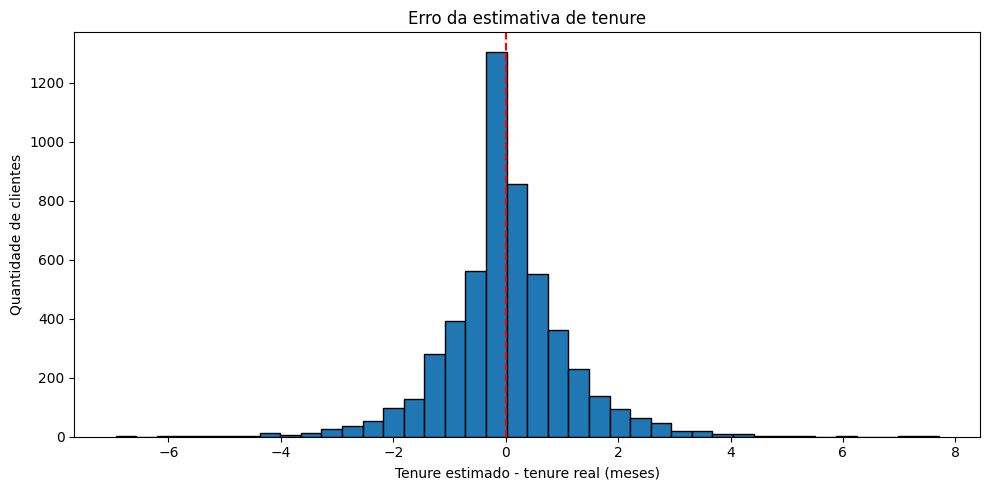

In [21]:
# 1. Cria uma cópia da base para investigação
# Mantém df1 inalterado
df_tenure = df1.copy()

# 2. Identifica os registros com tenure ausente
df_tenure['tenure_ausente'] = df_tenure['tenure'].isna()

# 3. Calcula uma estimativa de tenure a partir das cobranças
# Esta estimativa é apenas exploratória, não é uma imputação
df_tenure['tenure_estimado'] = (
    df_tenure['TotalCharges'] / df_tenure['MonthlyCharges']
)

# 4. Exibe os registros com tenure ausente
colunas_analise = [
    'tenure', 'MonthlyCharges', 'TotalCharges',
    'tenure_estimado', 'MonthlyIncome', 'Churn'
]

display(
    df_tenure.loc[
        df_tenure['tenure_ausente'],
        colunas_analise
    ].round(2)
)

# 5. Compara os grupos com e sem tenure ausente
resumo = df_tenure.groupby('tenure_ausente').agg(
    clientes=('Churn', 'size'),
    taxa_churn=('Churn', 'mean'),
    mensalidade_media=('MonthlyCharges', 'mean'),
    renda_media=('MonthlyIncome', 'mean'),
    totalcharges_medio=('TotalCharges', 'mean')
)

# Converte a taxa de churn para percentual
resumo['taxa_churn'] *= 100

print("Comparação entre os grupos:")
display(resumo.round(2))

# 6. Avalia a precisão da estimativa nos registros conhecidos
validacao = df_tenure.dropna(
    subset=['tenure', 'tenure_estimado']
).copy()

# Calcula a diferença entre tenure real e estimado
validacao['erro'] = (
    validacao['tenure_estimado'] - validacao['tenure']
)

# Calcula o erro absoluto
validacao['erro_absoluto'] = validacao['erro'].abs()

print("Avaliação da estimativa de tenure:")
print(f"Registros avaliados: {len(validacao)}")
print(f"Erro absoluto médio: {validacao['erro_absoluto'].mean():.2f} meses")
print(f"Erro absoluto mediano: {validacao['erro_absoluto'].median():.2f} meses")

# Percentual de estimativas com erro de até 1 mês
precisao_1_mes = (
    (validacao['erro_absoluto'] <= 1).mean() * 100
)

print(f"Estimativas com erro até 1 mês: {precisao_1_mes:.2f}%")

# 7. Visualiza a distribuição dos erros
plt.figure(figsize=(10, 5))
plt.hist(validacao['erro'], bins=40, edgecolor='black')
plt.axvline(0, color='red', linestyle='--')
plt.title('Erro da estimativa de tenure')
plt.xlabel('Tenure estimado - tenure real (meses)')
plt.ylabel('Quantidade de clientes')
plt.tight_layout()
plt.show()

In [22]:
# 1. Cria faixas de tempo de relacionamento
faixas = [-1, 6, 12, 24, 36, 48, 60, 72]

rotulos = [
    '0–6 meses',
    '7–12 meses',
    '13–24 meses',
    '25–36 meses',
    '37–48 meses',
    '49–60 meses',
    '61–72 meses'
]

# 2. Classifica os clientes com tenure conhecido por faixa
validacao['faixa_tenure'] = pd.cut(
    validacao['tenure'].astype(float),
    bins=faixas,
    labels=rotulos
)

# 3. Calcula o erro médio absoluto e a precisão por faixa
resultado_faixas = (
    validacao.groupby('faixa_tenure', observed=True)
    .agg(
        clientes=('erro_absoluto', 'size'),
        erro_medio=('erro_absoluto', 'mean'),
        erro_mediano=('erro_absoluto', 'median'),
        precisao_1_mes=('erro_absoluto', lambda x: (x <= 1).mean() * 100)
    )
    .round(2)
)

display(resultado_faixas)

,clientes,erro_medio,erro_mediano,precisao_1_mes
faixa_tenure,,,,
0–6 meses,1099,0.15,0.06,99.18
7–12 meses,551,0.49,0.39,87.84
13–24 meses,771,0.69,0.52,76.39
25–36 meses,637,0.89,0.73,63.74
37–48 meses,591,1.06,0.85,57.53
49–60 meses,630,1.08,0.85,58.25
61–72 meses,1059,1.16,0.88,55.05


Investigando TOTALCHARGES e imputando dados usando MonthlyCharges * tenure

In [23]:
# 1. Cria uma cópia para investigação, preservando df1
df_total = df1.copy()

# 2. Cria um indicador de ausência de TotalCharges
# 1 = Ausente; 0 = Preenchido
df_total['TotalCharges_ausente'] = (
    df_total['TotalCharges'].isna().astype('int64')
)

# 3. Quantifica os valores ausentes
print("Quantidade de valores ausentes:")
print(df_total['TotalCharges_ausente'].value_counts())

print("\nPercentual de valores ausentes:")
print(df_total['TotalCharges_ausente'].mean() * 100)

# 4. Verifica quantos clientes também possuem tenure ausente
print("\nRelação entre ausência de tenure e TotalCharges:")
display(pd.crosstab(
    df_total['tenure'].isna(),
    df_total['TotalCharges'].isna(),
    rownames=['tenure ausente'],
    colnames=['TotalCharges ausente']
))

# 5. Visualiza os registros com TotalCharges ausente
colunas_analise = [
    'tenure', 'MonthlyCharges', 'TotalCharges',
    'MonthlyIncome', 'Churn'
]

display(
    df_total.loc[
        df_total['TotalCharges_ausente'] == 1,
        colunas_analise
    ].head(30)
)


Quantidade de valores ausentes:
TotalCharges_ausente
0    5356
1     278
Name: count, dtype: int64

Percentual de valores ausentes:
4.934327298544551

Relação entre ausência de tenure e TotalCharges:


TotalCharges ausente,False,True
tenure ausente,,
False,5338,277
True,18,1


,tenure,MonthlyCharges,TotalCharges,MonthlyIncome,Churn
7,15,75.30,NaN,353,1
49,1,74.90,NaN,5422,1
64,4,88.95,NaN,1323,1
79,43,109.55,NaN,6588,1
122,46,54.35,NaN,5277,1
138,36,20.85,NaN,1408,0
139,11,19.25,NaN,8314,1
143,1,49.65,NaN,1768,1
162,45,18.85,NaN,7917,0
176,3,30.40,NaN,9137,0


Comparação entre clientes com e sem TotalCharges:


,clientes,taxa_churn,tenure_medio,tenure_mediano,mensalidade_media,renda_media
TotalCharges_ausente,,,,,,
0,5356,26.36,32.44,29.0,64.47,5101.32
1,278,33.09,29.7,25.0,67.28,5173.43



Distribuição dos contratos:


TotalCharges_ausente,0,1
Contract,,
Month-to-month,54.82,58.63
One year,21.21,18.71
Two year,23.97,22.66


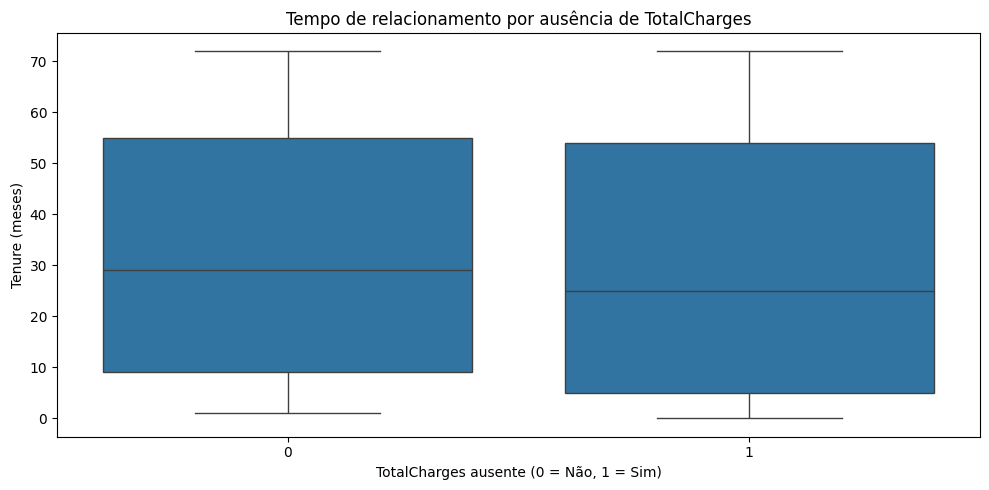

In [24]:
# 1. Compara características dos clientes com e sem TotalCharges
resumo_total = df_total.groupby('TotalCharges_ausente').agg(
    clientes=('Churn', 'size'),
    taxa_churn=('Churn', 'mean'),
    tenure_medio=('tenure', 'mean'),
    tenure_mediano=('tenure', 'median'),
    mensalidade_media=('MonthlyCharges', 'mean'),
    renda_media=('MonthlyIncome', 'mean')
)

# 2. Converte a taxa de churn em percentual
resumo_total['taxa_churn'] *= 100

# 3. Exibe o resultado
print("Comparação entre clientes com e sem TotalCharges:")
display(resumo_total.round(2))

# 4. Analisa a distribuição de contratos
# Utiliza df original, pois Contract já passou por One-Hot Encoding
print("\nDistribuição dos contratos:")
display(pd.crosstab(
    df['Contract'],
    df_total['TotalCharges_ausente'],
    normalize='columns'
).mul(100).round(2))

# 5. Compara visualmente a distribuição de tenure
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_total,
    x='TotalCharges_ausente',
    y='tenure'
)

plt.title('Tempo de relacionamento por ausência de TotalCharges')
plt.xlabel('TotalCharges ausente (0 = Não, 1 = Sim)')
plt.ylabel('Tenure (meses)')
plt.tight_layout()
plt.show()


MonthlyCharges * tenure

Registros avaliados: 5338
Erro absoluto médio (MAE): 44.59
Erro absoluto mediano: 28.40
RMSE: 66.56
Viés médio: -0.36


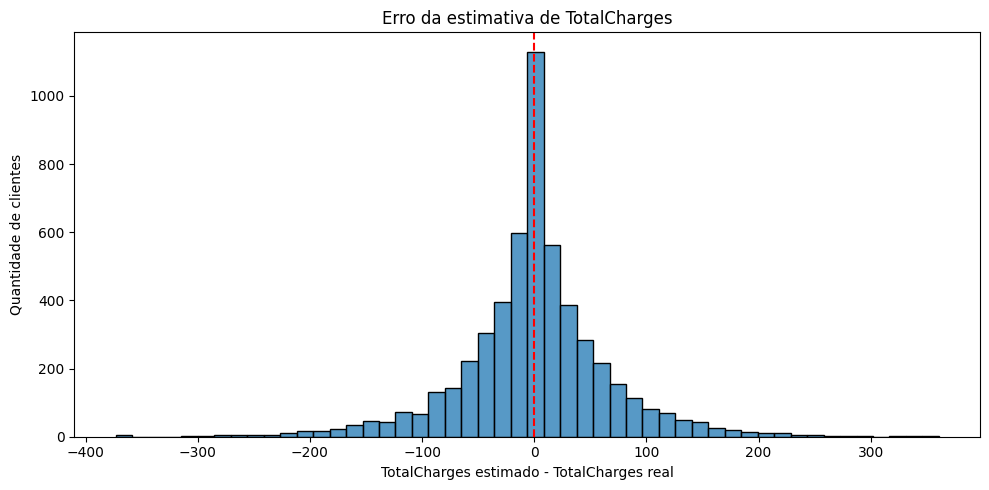

In [25]:

# 1. Seleciona clientes com TotalCharges e tenure conhecidos
validacao_total = df_total.dropna(
    subset=['TotalCharges', 'tenure', 'MonthlyCharges']
).copy()

# 2. Estima TotalCharges pela cobrança mensal e tempo de relacionamento
validacao_total['TotalCharges_estimado'] = (
    validacao_total['MonthlyCharges'] * validacao_total['tenure']
)

# 3. Calcula os erros da estimativa
validacao_total['erro'] = (
    validacao_total['TotalCharges_estimado']
    - validacao_total['TotalCharges']
)

validacao_total['erro_absoluto'] = (
    validacao_total['erro'].abs()
)

# 4. Calcula as métricas de precisão
mae = validacao_total['erro_absoluto'].mean()
mediana_erro = validacao_total['erro_absoluto'].median()
rmse = np.sqrt((validacao_total['erro'] ** 2).mean())
bias = validacao_total['erro'].mean()

print(f"Registros avaliados: {len(validacao_total)}")
print(f"Erro absoluto médio (MAE): {mae:.2f}")
print(f"Erro absoluto mediano: {mediana_erro:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"Viés médio: {bias:.2f}")

# 5. Visualiza a distribuição dos erros
plt.figure(figsize=(10, 5))

sns.histplot(
    validacao_total['erro'],
    bins=50
)

plt.axvline(0, color='red', linestyle='--')

plt.title('Erro da estimativa de TotalCharges')
plt.xlabel('TotalCharges estimado - TotalCharges real')
plt.ylabel('Quantidade de clientes')
plt.tight_layout()
plt.show()


,clientes,erro_medio,erro_mediano,vies_medio
faixa_tenure,,,,
0–6 meses,1099,7.55,2.65,0.01
7–12 meses,551,25.51,20.85,-1.97
13–24 meses,771,36.59,26.7,1.07
25–36 meses,637,49.79,39.8,2.39
37–48 meses,591,58.93,47.2,0.12
49–60 meses,630,64.0,51.75,-1.41
61–72 meses,1059,76.11,57.4,-2.26


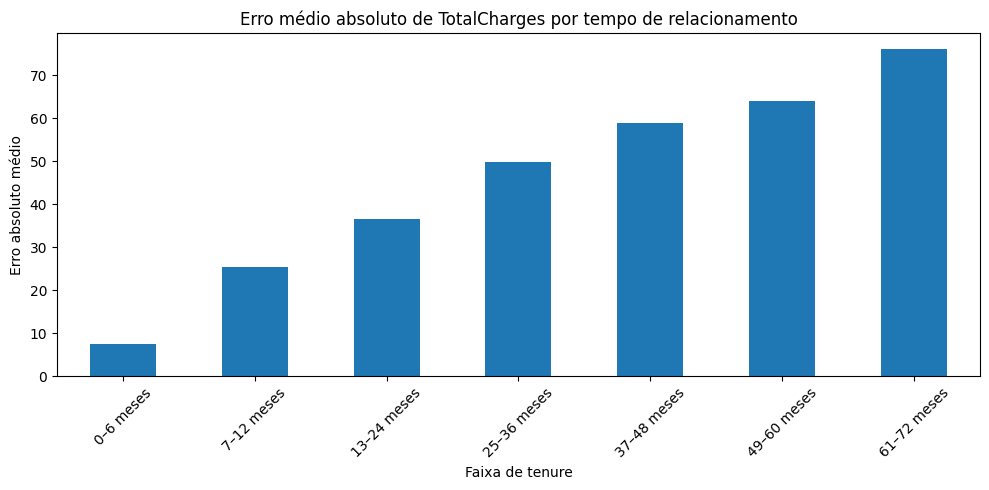

In [26]:
# 1. Define as faixas de tempo de relacionamento
faixas = [-1, 6, 12, 24, 36, 48, 60, 72]

rotulos = [
    '0–6 meses',
    '7–12 meses',
    '13–24 meses',
    '25–36 meses',
    '37–48 meses',
    '49–60 meses',
    '61–72 meses'
]

# 2. Classifica os clientes por faixa de tenure
validacao_total['faixa_tenure'] = pd.cut(
    validacao_total['tenure'].astype(float),
    bins=faixas,
    labels=rotulos
)

# 3. Calcula os erros por faixa
resultado_faixas_total = (
    validacao_total.groupby('faixa_tenure', observed=True)
    .agg(
        clientes=('erro_absoluto', 'size'),
        erro_medio=('erro_absoluto', 'mean'),
        erro_mediano=('erro_absoluto', 'median'),
        vies_medio=('erro', 'mean')
    )
    .round(2)
)

# 4. Exibe os resultados
display(resultado_faixas_total)

# 5. Visualiza o erro absoluto médio por faixa
plt.figure(figsize=(10, 5))

resultado_faixas_total['erro_medio'].plot(
    kind='bar'
)

plt.title('Erro médio absoluto de TotalCharges por tempo de relacionamento')
plt.xlabel('Faixa de tenure')
plt.ylabel('Erro absoluto médio')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [27]:
# Seleciona os clientes com TotalCharges ausente
ausentes_total = df1[df1['TotalCharges'].isna()]

# Verifica a disponibilidade e os valores de tenure
print("TotalCharges ausente:", len(ausentes_total))
print("Tenure também ausente:", ausentes_total['tenure'].isna().sum())
print("Tenure igual a zero:", (ausentes_total['tenure'] == 0).sum())
print("Tenure maior que zero:", (ausentes_total['tenure'] > 0).sum())

# Exibe a distribuição de tenure nesses registros
display(ausentes_total['tenure'].describe())


TotalCharges ausente: 278
Tenure também ausente: 1
Tenure igual a zero: 10
Tenure maior que zero: 267


count        277.0
mean     29.696751
std      24.777161
min            0.0
25%            5.0
50%           25.0
75%           54.0
max           72.0
Name: tenure, dtype: Float64

Ainda faltam TotalCharges para os casos com Tenure = 0.... inestigando

In [28]:

# 1. Seleciona todos os clientes com tenure igual a zero
clientes_tenure_zero = df1[df1['tenure'] == 0].copy()

# 2. Verifica quantos possuem TotalCharges preenchido ou ausente
print("Total de clientes com tenure = 0:", len(clientes_tenure_zero))

print("\nDistribuição da ausência de TotalCharges:")
print(clientes_tenure_zero['TotalCharges'].isna().value_counts())

# 3. Exibe as informações financeiras desses clientes
display(
    clientes_tenure_zero[
        ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
    ]
)

# 4. Calcula estatísticas dos valores conhecidos
print("\nEstatísticas de TotalCharges para tenure = 0:")
display(clientes_tenure_zero['TotalCharges'].describe())


Total de clientes com tenure = 0: 10

Distribuição da ausência de TotalCharges:
TotalCharges
True    10
Name: count, dtype: int64


,tenure,MonthlyCharges,TotalCharges,Churn
1409,0,20.00,NaN,0
2448,0,19.70,NaN,0
2526,0,52.55,NaN,0
3306,0,56.05,NaN,0
3483,0,25.35,NaN,0
4726,0,19.85,NaN,0
4851,0,20.25,NaN,0
5304,0,61.90,NaN,0
5378,0,25.75,NaN,0
5552,0,73.35,NaN,0



Estatísticas de TotalCharges para tenure = 0:


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: TotalCharges, dtype: float64

In [29]:
# 1. Cria uma cópia da base, preservando df1
df_imputacao = df1.copy()

# 2. Preserva a informação de ausência original
df_imputacao['TotalCharges_missing'] = (
    df_imputacao['TotalCharges'].isna().astype('int64')
)

# 3. Cria uma coluna com os valores existentes de TotalCharges
df_imputacao['TotalCharges_estimado'] = (
    df_imputacao['TotalCharges'].copy()
)

# 4. Identifica registros ausentes com tenure maior que zero
mascara_estimavel = (
    df_imputacao['TotalCharges'].isna()
    & (df_imputacao['tenure'] > 0).fillna(False)
)

# 5. Estima TotalCharges a partir de tenure e MonthlyCharges
df_imputacao.loc[
    mascara_estimavel, 'TotalCharges_estimado'
] = (
    df_imputacao.loc[mascara_estimavel, 'tenure']
    * df_imputacao.loc[mascara_estimavel, 'MonthlyCharges']
).astype(float)

# 6. Verifica a quantidade de valores ainda ausentes
print("Valores ausentes pós feature engineering MonthlyCharges * tenure:")
print(df_imputacao['TotalCharges_estimado'].isna().sum())

# 7. Exibe os registros que ainda precisam de tratamento
display(
    df_imputacao.loc[
        df_imputacao['TotalCharges_estimado'].isna(),
        ['tenure', 'MonthlyCharges', 'TotalCharges',
         'TotalCharges_estimado', 'Churn']
    ]
)


Valores ausentes pós feature engineering MonthlyCharges * tenure:
11


,tenure,MonthlyCharges,TotalCharges,TotalCharges_estimado,Churn
1097,<NA>,106.10,NaN,NaN,1
1409,0,20.00,NaN,NaN,0
2448,0,19.70,NaN,NaN,0
2526,0,52.55,NaN,NaN,0
3306,0,56.05,NaN,NaN,0
3483,0,25.35,NaN,NaN,0
4726,0,19.85,NaN,NaN,0
4851,0,20.25,NaN,NaN,0
5304,0,61.90,NaN,NaN,0
5378,0,25.75,NaN,NaN,0


In [30]:
# 1. Define os índices dos 11 registros 
indices = [1097, 1409, 2448, 2526, 3306, 3483,
           4726, 4851, 5304, 5378, 5552]

# Exibe as variáveis originais dos 11 registros
display(
    df.loc[
        indices,
        ['customerID', 'tenure', 'MonthlyCharges',
         'TotalCharges', 'Contract', 'Churn']
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
1097,9651-GTSAQ,unknown,106.10,NaN,One year,Yes
1409,2520-SGTTA,0,20.00,NaN,Two year,No
2448,2923-ARZLG,0,19.70,NaN,One year,No
2526,4472-LVYGI,0,52.55,NaN,Two year,No
3306,1371-DWPAZ,0,56.05,NaN,Two year,No
3483,3213-VVOLG,0,25.35,NaN,Two year,No
4726,7644-OMVMY,0,19.85,NaN,Two year,No
4851,3115-CZMZD,0,20.25,NaN,Two year,No
5304,2775-SEFEE,0,61.90,NaN,Two year,No
5378,4367-NUYAO,0,25.75,NaN,Two year,No


In [31]:
# 1. Garante que tenure e MonthlyCharges sejam numéricos
# Valores não numéricos são convertidos para nulos
df1['tenure'] = pd.to_numeric(df1['tenure'], errors='coerce')
df1['MonthlyCharges'] = pd.to_numeric(df1['MonthlyCharges'], errors='coerce')

# 2. Identifica registros inválidos
# tenure inválido: nulo ou negativo (zero é permitido)
# MonthlyCharges inválido: nulo, zero ou negativo
mascara_invalida = (
    df1['tenure'].isna()
    | (df1['tenure'] < 0).fillna(False)
    | df1['MonthlyCharges'].isna()
    | (df1['MonthlyCharges'] <= 0)
)

# 3. Armazena os índices dos registros inválidos
indices_excluidos = df1.index[mascara_invalida].tolist()

# 4. Exclui os registros inválidos
df1 = df1.loc[~mascara_invalida].copy()

# 5. Identifica clientes com tenure = 0 e TotalCharges ausente
# Preenche TotalCharges com o valor de MonthlyCharges
mascara_imputacao = (
    (df1['tenure'] == 0)
    & df1['TotalCharges'].isna()
)

# 6. Realiza a imputação
df1.loc[mascara_imputacao, 'TotalCharges'] = (
    df1.loc[mascara_imputacao, 'MonthlyCharges']
)

# 7. Exibe o resumo do tratamento
print(f"Registros excluídos: {len(indices_excluidos)}")
print(f"Índices excluídos: {indices_excluidos}")
print(f"Valores imputados em TotalCharges: {mascara_imputacao.sum()}")

# 8. Verifica os valores ausentes restantes
print("\nValores ausentes restantes:")
print(df1[['tenure', 'MonthlyCharges', 'TotalCharges']].isna().sum())


Registros excluídos: 19
Índices excluídos: [1059, 1097, 1791, 1984, 2361, 2372, 2641, 2896, 2936, 2959, 3153, 3300, 3388, 3476, 3515, 3837, 4875, 5324, 5328]
Valores imputados em TotalCharges: 10

Valores ausentes restantes:
tenure              0
MonthlyCharges      0
TotalCharges      267
dtype: int64


In [32]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5615 entries, 0 to 5633
Data columns (total 29 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   5615 non-null   Int64  
 1   SeniorCitizen                            5615 non-null   Int64  
 2   Partner                                  5615 non-null   Int64  
 3   Dependents                               5615 non-null   Int64  
 4   tenure                                   5615 non-null   Int64  
 5   PhoneService                             5615 non-null   Int64  
 6   MultipleLines                            5615 non-null   Int64  
 7   OnlineSecurity                           5615 non-null   Int64  
 8   OnlineBackup                             5615 non-null   Int64  
 9   DeviceProtection                         5615 non-null   Int64  
 10  TechSupport                              5615 non-nul

In [33]:
df1.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,5615.0,<NA>,<NA>,<NA>,0.496171,0.50003,0.0,0.0,0.0,1.0,1.0
SeniorCitizen,5615.0,<NA>,<NA>,<NA>,0.165272,0.371459,0.0,0.0,0.0,0.0,1.0
Partner,5615.0,<NA>,<NA>,<NA>,0.483526,0.499773,0.0,0.0,0.0,1.0,1.0
Dependents,5615.0,<NA>,<NA>,<NA>,0.299555,0.458104,0.0,0.0,0.0,1.0,1.0
tenure,5615.0,<NA>,<NA>,<NA>,32.306144,24.48471,0.0,9.0,29.0,55.0,72.0
PhoneService,5615.0,<NA>,<NA>,<NA>,0.899911,0.300145,0.0,1.0,1.0,1.0,1.0
MultipleLines,5615.0,<NA>,<NA>,<NA>,0.420125,0.493623,0.0,0.0,0.0,1.0,1.0
OnlineSecurity,5615.0,<NA>,<NA>,<NA>,0.283704,0.450835,0.0,0.0,0.0,1.0,1.0
OnlineBackup,5615.0,<NA>,<NA>,<NA>,0.344613,0.475284,0.0,0.0,0.0,1.0,1.0
DeviceProtection,5615.0,<NA>,<NA>,<NA>,0.34301,0.474757,0.0,0.0,0.0,1.0,1.0


Inputando TotalCharges

In [34]:
# 1. Identifica registros com TotalCharges ausente e tenure positivo
mascara_imputacao = (
    df1['TotalCharges'].isna()
    & (df1['tenure'] > 0)
    & (df1['MonthlyCharges'] > 0)
).fillna(False)

# 2. Registra a quantidade de valores que serão imputados
quantidade_imputada = mascara_imputacao.sum()

# 3. Imputa TotalCharges multiplicando tenure por MonthlyCharges
df1.loc[mascara_imputacao, 'TotalCharges'] = (
    df1.loc[mascara_imputacao, 'tenure'].astype(float)
    * df1.loc[mascara_imputacao, 'MonthlyCharges']
)

# 4. Exibe o resumo do tratamento
print(f"Valores imputados: {quantidade_imputada}")
print(f"Valores ausentes restantes: {df1['TotalCharges'].isna().sum()}")


Valores imputados: 267
Valores ausentes restantes: 0


Criando ABT

In [35]:
# 1. Cria a Analytical Base Table (ABT) a partir da base tratada
ABT = df1.copy()

# 2. Remove CustomerFeedback da ABT de modelagem
# Texto não estruturado com potencial vazamento de informação
ABT = ABT.drop(columns=['CustomerFeedback'], errors='ignore')

# 3. Verifica as dimensões finais
print(f"Total de registros: {ABT.shape[0]}")
print(f"Total de variáveis: {ABT.shape[1]}")

# 4. Confere a existência de valores ausentes
print("\nValores ausentes por variável:")
print(ABT.isna().sum())

# 5. Confirma que não existem valores ausentes ou colunas não numéricas
assert ABT.isna().sum().sum() == 0, "Existem valores ausentes na ABT!"
assert len(ABT.select_dtypes(exclude='number').columns) == 0, \
    "Existem variáveis não numéricas na ABT!"


Total de registros: 5615
Total de variáveis: 28

Valores ausentes por variável:
gender                                     0
SeniorCitizen                              0
Partner                                    0
Dependents                                 0
tenure                                     0
PhoneService                               0
MultipleLines                              0
OnlineSecurity                             0
OnlineBackup                               0
DeviceProtection                           0
TechSupport                                0
StreamingTV                                0
StreamingMovies                            0
PaperlessBilling                           0
MonthlyCharges                             0
TotalCharges                               0
Churn                                      0
MonthlyIncome                              0
PaymentMethod_Bank transfer (automatic)    0
PaymentMethod_Credit card (automatic)      0
PaymentMethod_Electr

In [36]:
ABT.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5615 entries, 0 to 5633
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   5615 non-null   Int64  
 1   SeniorCitizen                            5615 non-null   Int64  
 2   Partner                                  5615 non-null   Int64  
 3   Dependents                               5615 non-null   Int64  
 4   tenure                                   5615 non-null   Int64  
 5   PhoneService                             5615 non-null   Int64  
 6   MultipleLines                            5615 non-null   Int64  
 7   OnlineSecurity                           5615 non-null   Int64  
 8   OnlineBackup                             5615 non-null   Int64  
 9   DeviceProtection                         5615 non-null   Int64  
 10  TechSupport                              5615 non-nul

In [37]:
display(ABT.head(20))

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,0,1,1,52,1,0,0,1,1,...,0,0,1,0,1,0,0,0,1,0
1,0,0,1,1,33,1,0,0,0,1,...,0,0,0,1,1,0,0,0,1,0
2,1,1,0,0,22,1,0,0,0,0,...,0,0,0,1,0,0,1,0,1,0
3,1,1,1,1,28,0,0,0,0,0,...,0,0,1,0,1,0,0,1,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,0,1,0,0,1,0,1,0,0
5,0,0,1,1,70,1,1,0,1,0,...,1,0,0,0,0,1,0,0,0,1
6,1,0,0,0,3,0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
7,1,1,0,0,15,1,0,0,1,0,...,0,1,0,0,0,1,0,1,0,0
8,0,0,1,1,42,1,0,1,1,0,...,0,0,0,1,1,0,0,1,0,0
9,0,0,0,1,25,1,0,0,0,0,...,0,0,0,1,0,0,1,1,0,0


In [38]:
ABT.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
gender,5615.0,0.496171,0.50003,0.0,0.0,0.0,1.0,1.0
SeniorCitizen,5615.0,0.165272,0.371459,0.0,0.0,0.0,0.0,1.0
Partner,5615.0,0.483526,0.499773,0.0,0.0,0.0,1.0,1.0
Dependents,5615.0,0.299555,0.458104,0.0,0.0,0.0,1.0,1.0
tenure,5615.0,32.306144,24.48471,0.0,9.0,29.0,55.0,72.0
PhoneService,5615.0,0.899911,0.300145,0.0,1.0,1.0,1.0,1.0
MultipleLines,5615.0,0.420125,0.493623,0.0,0.0,0.0,1.0,1.0
OnlineSecurity,5615.0,0.283704,0.450835,0.0,0.0,0.0,1.0,1.0
OnlineBackup,5615.0,0.344613,0.475284,0.0,0.0,0.0,1.0,1.0
DeviceProtection,5615.0,0.34301,0.474757,0.0,0.0,0.0,1.0,1.0


Preparando dados para modelagem

Logistic Regression

VALIDAÇÃO CRUZADA — LOGISTIC REGRESSION


,Métrica,Média CV,Desvio CV
0,ROC-AUC,0.8369,0.0152
1,Average Precision,0.6446,0.0324
2,Accuracy,0.7974,0.0155
3,Precision,0.6443,0.0272
4,Recall,0.5331,0.0654
5,F1-score,0.5819,0.0461
6,Log Loss,0.4282,0.0153
7,Brier Score,0.1392,0.0056



TESTE — LOGISTIC REGRESSION


,Modelo,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
0,Logistic Regression,0.8525,0.6754,0.821,0.6885,0.5987,0.6404,0.41,0.1323


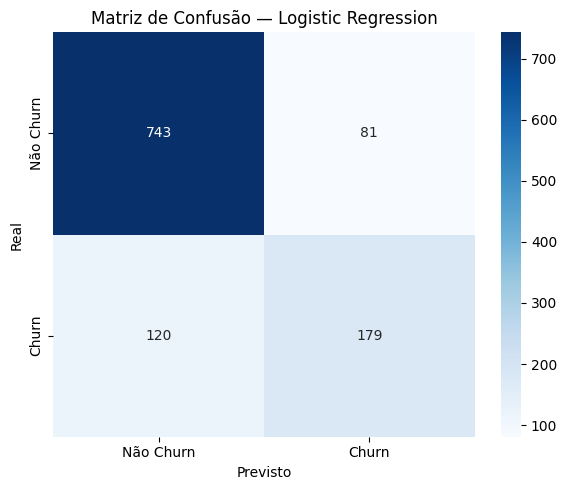

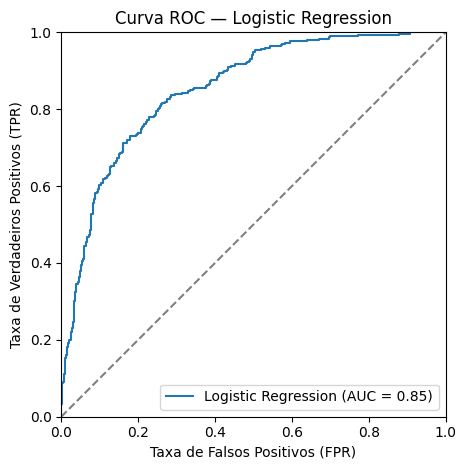

In [39]:
# 1. Separa as variáveis preditoras (X) da variável-alvo (y)
X = ABT.drop(columns=['Churn']).astype('float64')
y = ABT['Churn'].astype('int64')

# 2. Define as variáveis quantitativas que serão padronizadas
num_cols = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
    'MonthlyIncome'
]

# 3. Divide a base em treino (80%) e teste (20%)
# A estratificação mantém a proporção de churn nos dois conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 4. Configura o pré-processamento
# Padroniza apenas as variáveis 
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), num_cols)
    ],
    remainder='passthrough'
)

# 5. Cria o pipeline da regressão logística
pipeline_logistic = Pipeline([
    ('preprocessor', preprocessor),
    ('modelo', LogisticRegression(
        max_iter=1000,
        solver='lbfgs',
        random_state=42
    ))
])

# 6. Configura a validação cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 7. Define as métricas para validação cruzada
scoring = {
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'neg_log_loss': 'neg_log_loss',
    'neg_brier_score': 'neg_brier_score'
}

# 8. Executa a validação cruzada somente no conjunto de treino
# O StandardScaler é reajustado dentro de cada fold
cv_results = cross_validate(
    pipeline_logistic,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# 9. Organiza as métricas da validação cruzada
metricas_cv = pd.DataFrame({
    'Métrica': [
        'ROC-AUC', 'Average Precision', 'Accuracy',
        'Precision', 'Recall', 'F1-score',
        'Log Loss', 'Brier Score'
    ],
    'Média CV': [
        cv_results['test_roc_auc'].mean(),
        cv_results['test_average_precision'].mean(),
        cv_results['test_accuracy'].mean(),
        cv_results['test_precision'].mean(),
        cv_results['test_recall'].mean(),
        cv_results['test_f1'].mean(),
        -cv_results['test_neg_log_loss'].mean(),
        -cv_results['test_neg_brier_score'].mean()
    ],
    'Desvio CV': [
        cv_results['test_roc_auc'].std(),
        cv_results['test_average_precision'].std(),
        cv_results['test_accuracy'].std(),
        cv_results['test_precision'].std(),
        cv_results['test_recall'].std(),
        cv_results['test_f1'].std(),
        cv_results['test_neg_log_loss'].std(),
        cv_results['test_neg_brier_score'].std()
    ]
})

print("VALIDAÇÃO CRUZADA — LOGISTIC REGRESSION")
display(metricas_cv.round(4))

# 10. Treina o modelo com todo o conjunto de treinamento
pipeline_logistic.fit(X_train, y_train)

# 11. Gera previsões e probabilidades no conjunto de teste
y_pred = pipeline_logistic.predict(X_test)
y_proba = pipeline_logistic.predict_proba(X_test)[:, 1]

# 12. Calcula as métricas no conjunto de teste
metricas_teste = {
    'Modelo': 'Logistic Regression',
    'ROC-AUC': roc_auc_score(y_test, y_proba),
    'Average Precision': average_precision_score(y_test, y_proba),
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-score': f1_score(y_test, y_pred, zero_division=0),
    'Log Loss': log_loss(y_test, y_proba),
    'Brier Score': brier_score_loss(y_test, y_proba)
}

# 13. Armazena os resultados para comparação futura
resultados_modelos = pd.DataFrame([metricas_teste])

print("\nTESTE — LOGISTIC REGRESSION")
display(resultados_modelos.round(4))

# 14. Cria a matriz de confusão
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Não Churn', 'Churn'],
    yticklabels=['Não Churn', 'Churn']
)
plt.title('Matriz de Confusão — Logistic Regression')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

# 15. Exibe a curva ROC da Regressão Logística
RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    name='Logistic Regression'
)

plt.plot(
    [0, 1], [0, 1],
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.title('Curva ROC — Logistic Regression')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

K-Nearest Neighbors (KNN)

VALIDAÇÃO CRUZADA — KNN


,Métrica,Média CV,Desvio CV
0,ROC-AUC,0.7797,0.0170
1,Average Precision,0.5165,0.0280
2,Accuracy,0.7663,0.0114
3,Precision,0.5681,0.0227
4,Recall,0.5138,0.0329
5,F1-score,0.5392,0.0253
6,Log Loss,1.6467,0.2312
7,Brier Score,0.1643,0.0085



TESTE — KNN


,Modelo,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
0,KNN,0.7834,0.5177,0.7631,0.5567,0.5418,0.5492,1.4717,0.1624


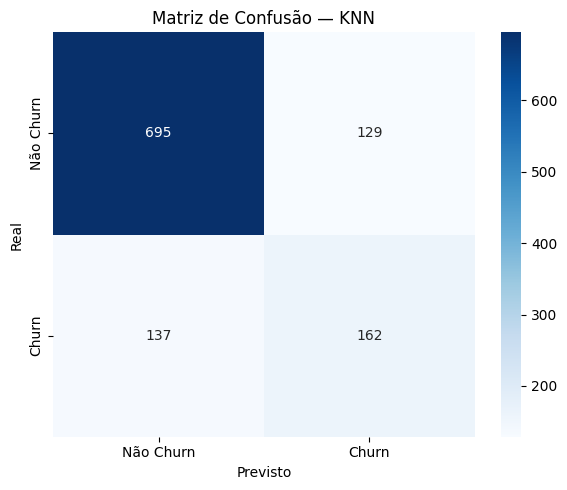

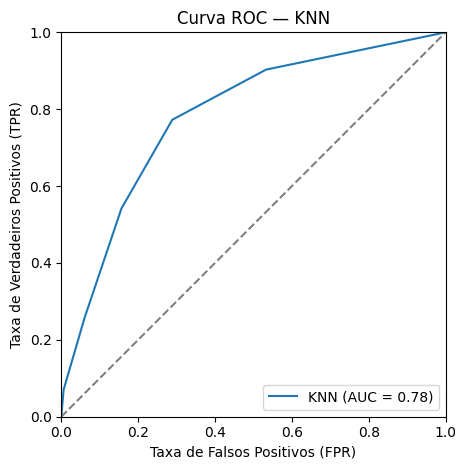

In [40]:
# 1. Cria o pipeline do KNN reutilizando o pré-processamento definido na Logistic Regression
pipeline_knn = Pipeline([
    ('preprocessor', preprocessor),
    ('modelo', KNeighborsClassifier(
        n_neighbors=5,       # Considera os 5 vizinhos mais próximos
        weights='uniform',   # Todos os vizinhos possuem o mesmo peso
        metric='euclidean'   # Utiliza distância euclidiana
    ))
])

# 2. Executa validação cruzada nos mesmos 5 folds reutilizando X_train, y_train, cv e scoring
cv_results_knn = cross_validate(
    pipeline_knn,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# 3. Organiza as métricas da validação cruzada
metricas_cv_knn = pd.DataFrame({
    'Métrica': [
        'ROC-AUC', 'Average Precision', 'Accuracy',
        'Precision', 'Recall', 'F1-score',
        'Log Loss', 'Brier Score'
    ],
    'Média CV': [
        cv_results_knn['test_roc_auc'].mean(),
        cv_results_knn['test_average_precision'].mean(),
        cv_results_knn['test_accuracy'].mean(),
        cv_results_knn['test_precision'].mean(),
        cv_results_knn['test_recall'].mean(),
        cv_results_knn['test_f1'].mean(),
        -cv_results_knn['test_neg_log_loss'].mean(),
        -cv_results_knn['test_neg_brier_score'].mean()
    ],
    'Desvio CV': [
        cv_results_knn['test_roc_auc'].std(),
        cv_results_knn['test_average_precision'].std(),
        cv_results_knn['test_accuracy'].std(),
        cv_results_knn['test_precision'].std(),
        cv_results_knn['test_recall'].std(),
        cv_results_knn['test_f1'].std(),
        cv_results_knn['test_neg_log_loss'].std(),
        cv_results_knn['test_neg_brier_score'].std()
    ]
})

print("VALIDAÇÃO CRUZADA — KNN")
display(metricas_cv_knn.round(4))

# 4. Treina o KNN no conjunto completo de treinamento
pipeline_knn.fit(X_train, y_train)

# 5. Gera previsões e probabilidades no conjunto de teste
y_pred_knn = pipeline_knn.predict(X_test)
y_proba_knn = pipeline_knn.predict_proba(X_test)[:, 1]

# 6. Calcula as métricas no conjunto de teste
metricas_teste_knn = {
    'Modelo': 'KNN',
    'ROC-AUC': roc_auc_score(y_test, y_proba_knn),
    'Average Precision': average_precision_score(y_test, y_proba_knn),
    'Accuracy': accuracy_score(y_test, y_pred_knn),
    'Precision': precision_score(y_test, y_pred_knn, zero_division=0),
    'Recall': recall_score(y_test, y_pred_knn, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_knn, zero_division=0),
    'Log Loss': log_loss(y_test, y_proba_knn),
    'Brier Score': brier_score_loss(y_test, y_proba_knn)
}

# 7. Armazena os resultados do KNN
resultados_knn = pd.DataFrame([metricas_teste_knn])

print("\nTESTE — KNN")
display(resultados_knn.round(4))

# 8. Exibe a matriz de confusão
matriz_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Não Churn', 'Churn'],
    yticklabels=['Não Churn', 'Churn']
)
plt.title('Matriz de Confusão — KNN')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

# 9. Exibe a curva ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_knn,
    name='KNN'
)

plt.plot(
    [0, 1], [0, 1],
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.title('Curva ROC — KNN')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Multi-Layer Perceptron (MLP)

VALIDAÇÃO CRUZADA — MLP


,Métrica,Média CV,Desvio CV
0,ROC-AUC,0.8331,0.0129
1,Average Precision,0.6323,0.0282
2,Accuracy,0.7916,0.0119
3,Precision,0.6359,0.0261
4,Recall,0.5122,0.0681
5,F1-score,0.5649,0.0431
6,Log Loss,0.4326,0.0143
7,Brier Score,0.1411,0.0056



TESTE — MLP


,Modelo,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
0,MLP,0.8434,0.6421,0.8094,0.6592,0.5886,0.6219,0.4195,0.1362


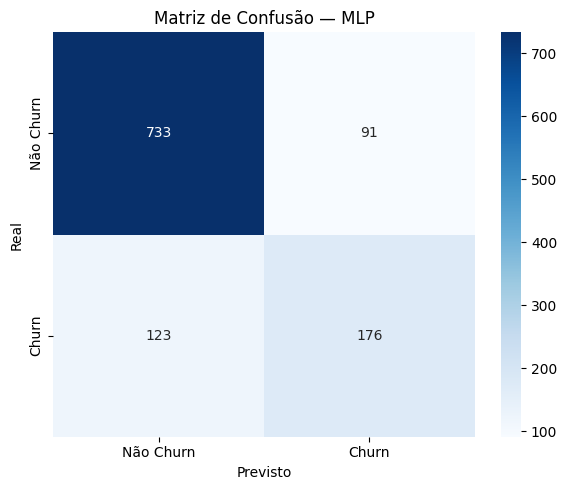

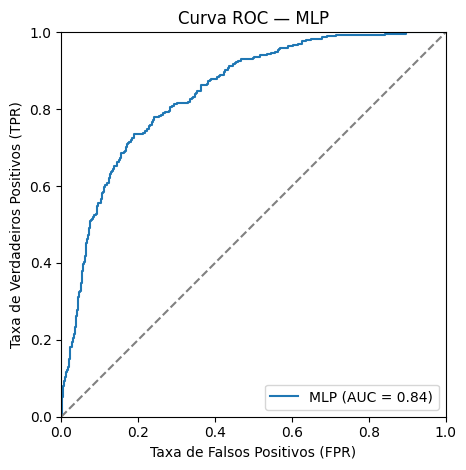

In [41]:
# 1. Cria o pipeline do MLP
pipeline_mlp = Pipeline([
    ('preprocessor', preprocessor),
    ('modelo', MLPClassifier(
        hidden_layer_sizes=(64, 32),  # Duas camadas ocultas: 64 e 32 neurônios
        activation='relu',            # Função de ativação ReLU
        solver='adam',                # Otimizador Adam
        alpha=0.001,                  # Regularização L2
        learning_rate_init=0.001,     # Taxa de aprendizado inicial
        max_iter=1000,                # Número máximo de épocas de treinamento
        early_stopping=True,          # Interrompe treinamento se não houver melhora
        validation_fraction=0.10,     # Reserva 10% do treino interno para validação
        n_iter_no_change=20,          # Paciência de 20 épocas sem melhora suficiente
        random_state=42
    ))
])

# 2. Executa validação cruzada nos mesmos 5 folds
cv_results_mlp = cross_validate(
    pipeline_mlp,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# 3. Organiza as métricas da validação cruzada
metricas_cv_mlp = pd.DataFrame({
    'Métrica': [
        'ROC-AUC', 'Average Precision', 'Accuracy',
        'Precision', 'Recall', 'F1-score',
        'Log Loss', 'Brier Score'
    ],
    'Média CV': [
        cv_results_mlp['test_roc_auc'].mean(),
        cv_results_mlp['test_average_precision'].mean(),
        cv_results_mlp['test_accuracy'].mean(),
        cv_results_mlp['test_precision'].mean(),
        cv_results_mlp['test_recall'].mean(),
        cv_results_mlp['test_f1'].mean(),
        -cv_results_mlp['test_neg_log_loss'].mean(),
        -cv_results_mlp['test_neg_brier_score'].mean()
    ],
    'Desvio CV': [
        cv_results_mlp['test_roc_auc'].std(),
        cv_results_mlp['test_average_precision'].std(),
        cv_results_mlp['test_accuracy'].std(),
        cv_results_mlp['test_precision'].std(),
        cv_results_mlp['test_recall'].std(),
        cv_results_mlp['test_f1'].std(),
        cv_results_mlp['test_neg_log_loss'].std(),
        cv_results_mlp['test_neg_brier_score'].std()
    ]
})

print("VALIDAÇÃO CRUZADA — MLP")
display(metricas_cv_mlp.round(4))

# 4. Treina o MLP utilizando todo o conjunto de treinamento
pipeline_mlp.fit(X_train, y_train)

# 5. Gera previsões e probabilidades no conjunto de teste
y_pred_mlp = pipeline_mlp.predict(X_test)
y_proba_mlp = pipeline_mlp.predict_proba(X_test)[:, 1]

# 6. Calcula as métricas do conjunto de teste
metricas_teste_mlp = {
    'Modelo': 'MLP',
    'ROC-AUC': roc_auc_score(y_test, y_proba_mlp),
    'Average Precision': average_precision_score(y_test, y_proba_mlp),
    'Accuracy': accuracy_score(y_test, y_pred_mlp),
    'Precision': precision_score(y_test, y_pred_mlp, zero_division=0),
    'Recall': recall_score(y_test, y_pred_mlp, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_mlp, zero_division=0),
    'Log Loss': log_loss(y_test, y_proba_mlp),
    'Brier Score': brier_score_loss(y_test, y_proba_mlp)
}

# 7. Armazena os resultados do MLP
resultados_mlp = pd.DataFrame([metricas_teste_mlp])

print("\nTESTE — MLP")
display(resultados_mlp.round(4))

# 8. Cria a matriz de confusão
matriz_mlp = confusion_matrix(y_test, y_pred_mlp)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_mlp,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Não Churn', 'Churn'],
    yticklabels=['Não Churn', 'Churn']
)

plt.title('Matriz de Confusão — MLP')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

# 9. Exibe a curva ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_mlp,
    name='MLP'
)

plt.plot(
    [0, 1], [0, 1],
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.title('Curva ROC — MLP')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Decision Tree

VALIDAÇÃO CRUZADA — DECISION TREE


,Métrica,Média CV,Desvio CV
0,ROC-AUC,0.8213,0.0126
1,Average Precision,0.5925,0.0188
2,Accuracy,0.7883,0.0144
3,Precision,0.6147,0.0335
4,Recall,0.5580,0.0408
5,F1-score,0.5838,0.0278
6,Log Loss,0.5093,0.0564
7,Brier Score,0.1455,0.0054



TESTE — DECISION TREE


,Modelo,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
0,Decision Tree,0.8242,0.6154,0.7943,0.6197,0.5886,0.6038,0.5814,0.1428


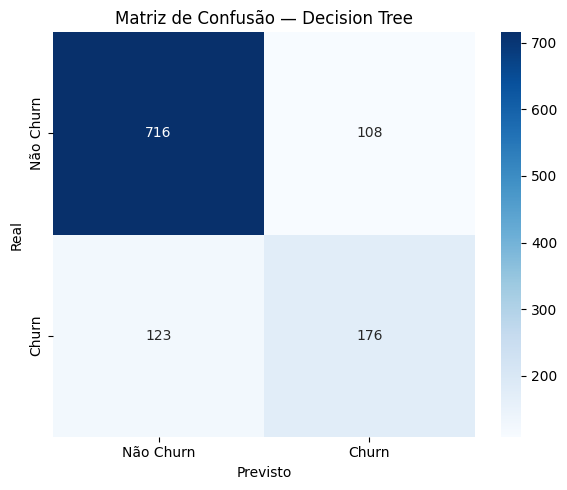

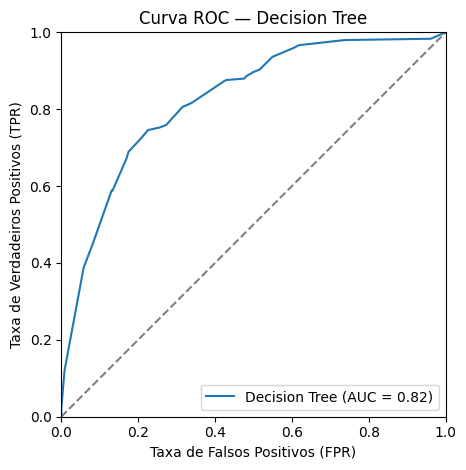

In [42]:
# 1. Cria o modelo Decision Tree
modelo_dt = DecisionTreeClassifier(
    criterion='gini',       # Critério utilizado para escolher as divisões
    max_depth=5,            # Limita a profundidade para reduzir overfitting
    min_samples_leaf=10,    # Exige no mínimo 10 clientes por folha
    random_state=42
)

# 2. Executa validação cruzada nos mesmos cinco folds
cv_results_dt = cross_validate(
    modelo_dt,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# 3. Organiza as métricas da validação cruzada
metricas_cv_dt = pd.DataFrame({
    'Métrica': [
        'ROC-AUC', 'Average Precision', 'Accuracy',
        'Precision', 'Recall', 'F1-score',
        'Log Loss', 'Brier Score'
    ],
    'Média CV': [
        cv_results_dt['test_roc_auc'].mean(),
        cv_results_dt['test_average_precision'].mean(),
        cv_results_dt['test_accuracy'].mean(),
        cv_results_dt['test_precision'].mean(),
        cv_results_dt['test_recall'].mean(),
        cv_results_dt['test_f1'].mean(),
        -cv_results_dt['test_neg_log_loss'].mean(),
        -cv_results_dt['test_neg_brier_score'].mean()
    ],
    'Desvio CV': [
        cv_results_dt['test_roc_auc'].std(),
        cv_results_dt['test_average_precision'].std(),
        cv_results_dt['test_accuracy'].std(),
        cv_results_dt['test_precision'].std(),
        cv_results_dt['test_recall'].std(),
        cv_results_dt['test_f1'].std(),
        cv_results_dt['test_neg_log_loss'].std(),
        cv_results_dt['test_neg_brier_score'].std()
    ]
})

print("VALIDAÇÃO CRUZADA — DECISION TREE")
display(metricas_cv_dt.round(4))

# 4. Treina a árvore com todo o conjunto de treinamento
modelo_dt.fit(X_train, y_train)

# 5. Gera previsões e probabilidades no conjunto de teste
y_pred_dt = modelo_dt.predict(X_test)
y_proba_dt = modelo_dt.predict_proba(X_test)[:, 1]

# 6. Calcula as métricas no conjunto de teste
metricas_teste_dt = {
    'Modelo': 'Decision Tree',
    'ROC-AUC': roc_auc_score(y_test, y_proba_dt),
    'Average Precision': average_precision_score(y_test, y_proba_dt),
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt, zero_division=0),
    'Recall': recall_score(y_test, y_pred_dt, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_dt, zero_division=0),
    'Log Loss': log_loss(y_test, y_proba_dt),
    'Brier Score': brier_score_loss(y_test, y_proba_dt)
}

# 7. Armazena os resultados para comparação posterior
resultados_dt = pd.DataFrame([metricas_teste_dt])

print("\nTESTE — DECISION TREE")
display(resultados_dt.round(4))

# 8. Cria a matriz de confusão
matriz_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Não Churn', 'Churn'],
    yticklabels=['Não Churn', 'Churn']
)

plt.title('Matriz de Confusão — Decision Tree')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

# 9. Exibe a curva ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_dt,
    name='Decision Tree'
)

plt.plot(
    [0, 1], [0, 1],
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.title('Curva ROC — Decision Tree')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

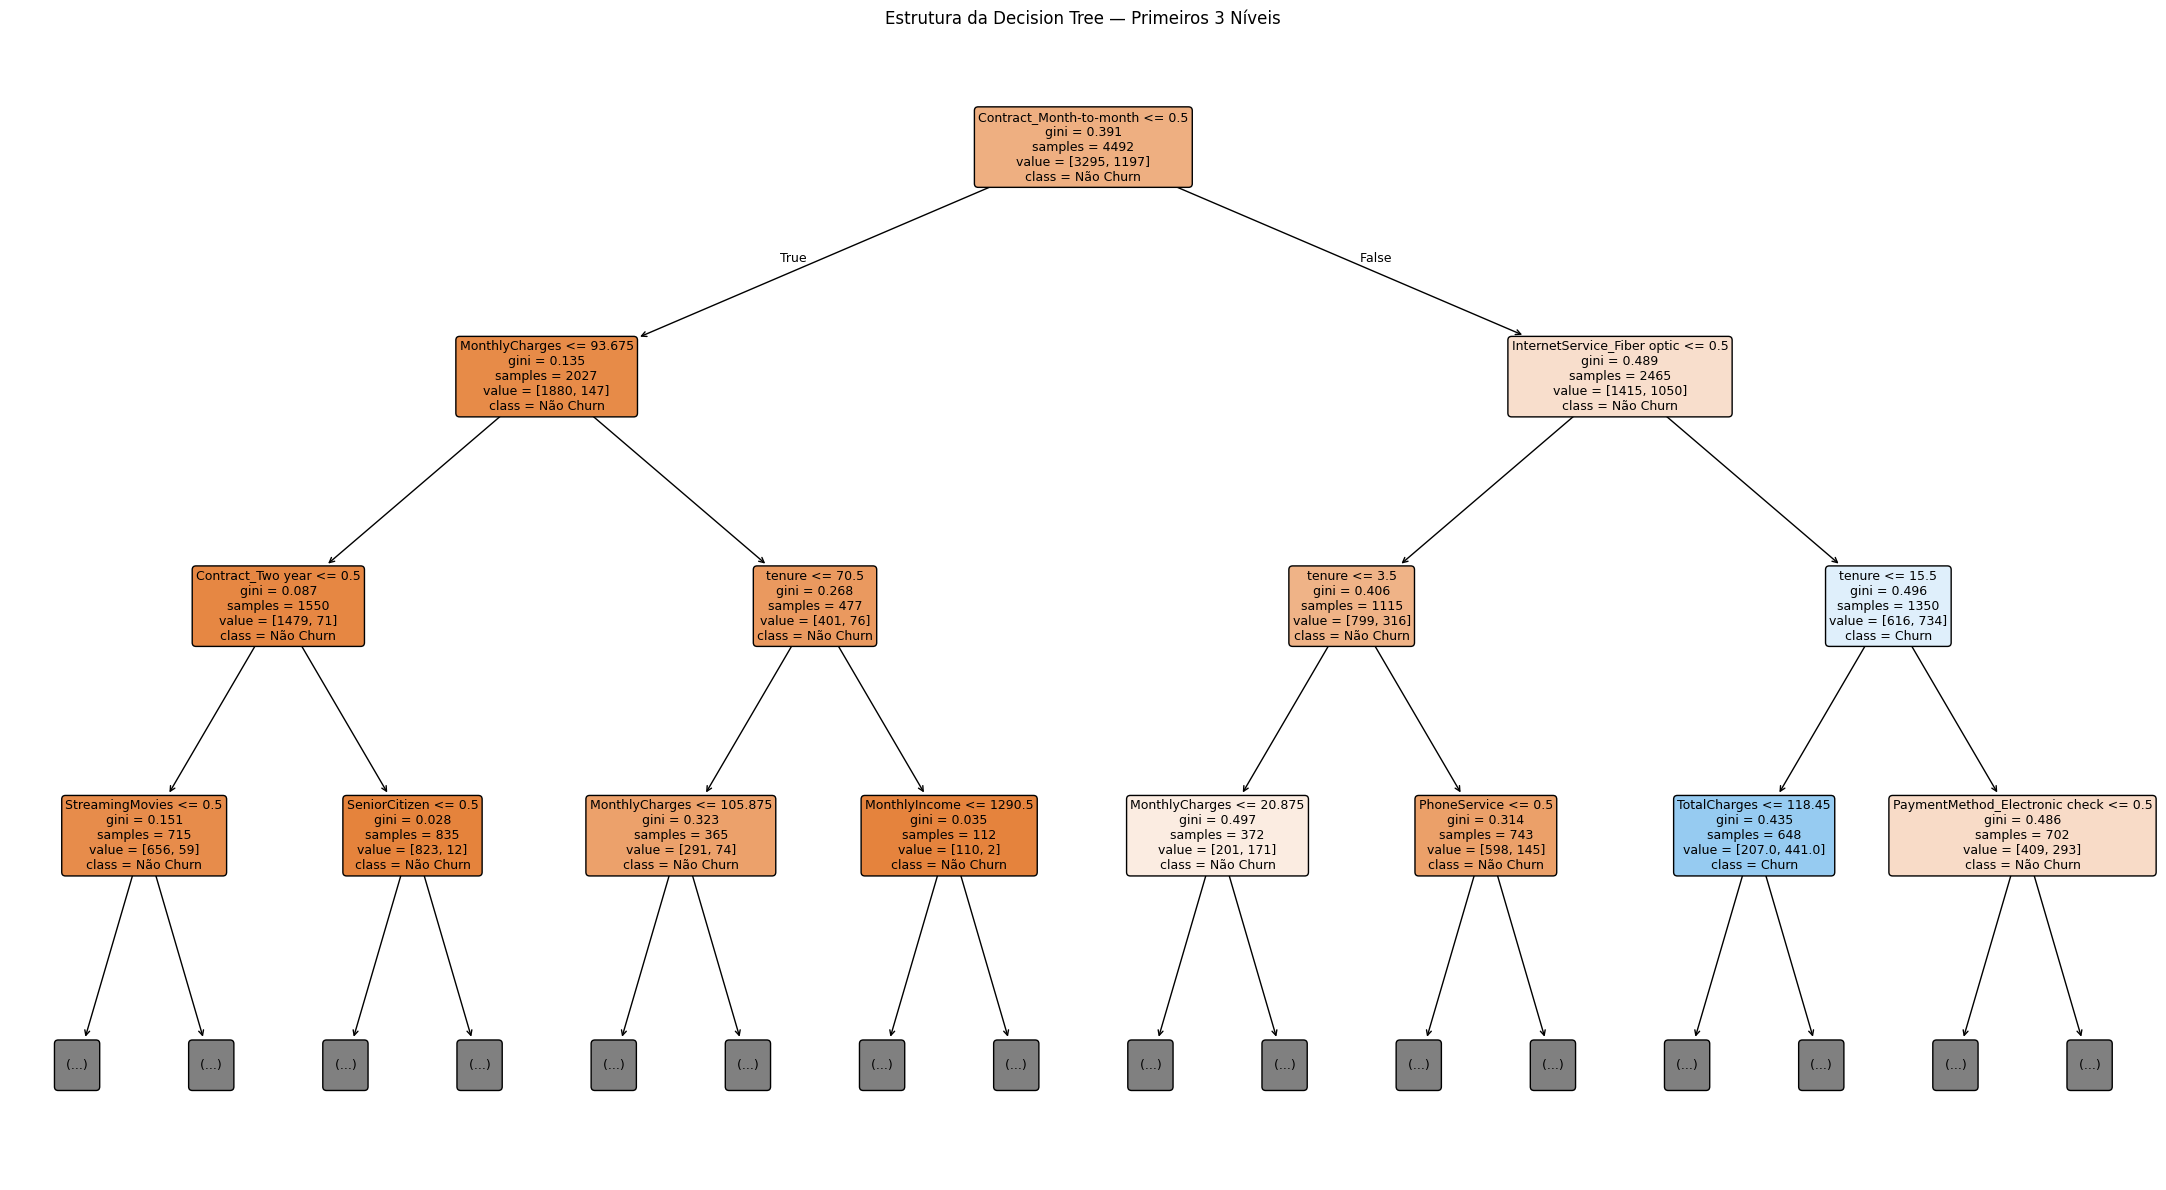

In [43]:
plt.figure(figsize=(22, 12))

# Visualiza os níveis da árvore treinada
plot_tree(
    modelo_dt,
    feature_names=X_train.columns,
    class_names=['Não Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3
)

plt.title('Estrutura da Decision Tree — Primeiros 3 Níveis')
plt.tight_layout()
plt.show()

Random Forest

VALIDAÇÃO CRUZADA — RANDOM FOREST


,Métrica,Média CV,Desvio CV
0,ROC-AUC,0.8397,0.0138
1,Average Precision,0.6427,0.0281
2,Accuracy,0.7985,0.0122
3,Precision,0.6609,0.0173
4,Recall,0.4988,0.0635
5,F1-score,0.5667,0.0458
6,Log Loss,0.4255,0.0134
7,Brier Score,0.1382,0.0055



TESTE — RANDOM FOREST


,Modelo,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
0,Random Forest,0.8442,0.6617,0.8059,0.6695,0.5351,0.5948,0.4186,0.1357


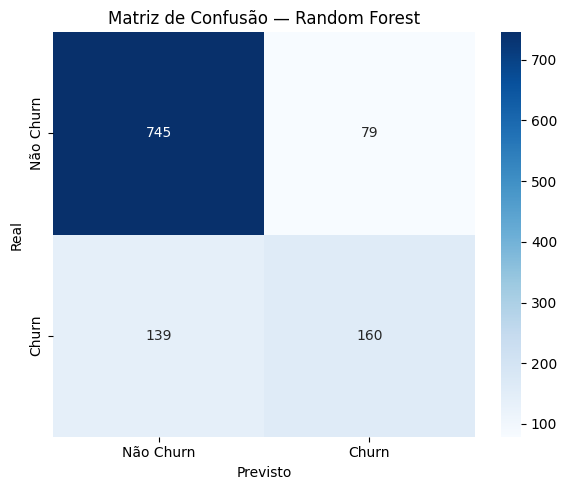

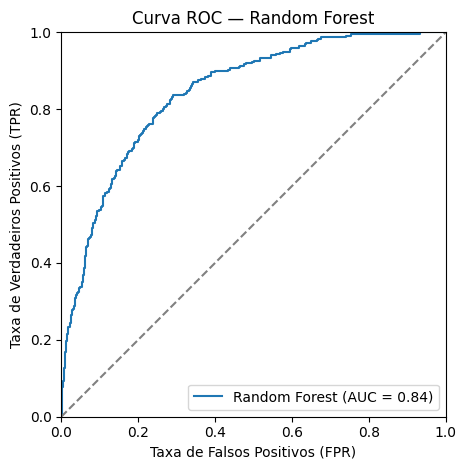

In [44]:
# 1. Cria o modelo Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=200,       # Número de árvores da floresta
    criterion='gini',       # Critério de impureza para as divisões
    max_depth=10,          # Limita a profundidade das árvores
    min_samples_leaf=5,    # Exige no mínimo 5 clientes por folha
    max_features='sqrt',   # Considera sqrt(n_features) em cada divisão
    bootstrap=True,        # Utiliza amostras com reposição
    random_state=42,
    n_jobs=1               # Evita paralelismo aninhado durante a validação
)

# 2. Executa validação cruzada nos mesmos folds
cv_results_rf = cross_validate(
    modelo_rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# 3. Organiza as métricas da validação cruzada
metricas_cv_rf = pd.DataFrame({
    'Métrica': [
        'ROC-AUC', 'Average Precision', 'Accuracy',
        'Precision', 'Recall', 'F1-score',
        'Log Loss', 'Brier Score'
    ],
    'Média CV': [
        cv_results_rf['test_roc_auc'].mean(),
        cv_results_rf['test_average_precision'].mean(),
        cv_results_rf['test_accuracy'].mean(),
        cv_results_rf['test_precision'].mean(),
        cv_results_rf['test_recall'].mean(),
        cv_results_rf['test_f1'].mean(),
        -cv_results_rf['test_neg_log_loss'].mean(),
        -cv_results_rf['test_neg_brier_score'].mean()
    ],
    'Desvio CV': [
        cv_results_rf['test_roc_auc'].std(),
        cv_results_rf['test_average_precision'].std(),
        cv_results_rf['test_accuracy'].std(),
        cv_results_rf['test_precision'].std(),
        cv_results_rf['test_recall'].std(),
        cv_results_rf['test_f1'].std(),
        cv_results_rf['test_neg_log_loss'].std(),
        cv_results_rf['test_neg_brier_score'].std()
    ]
})

print("VALIDAÇÃO CRUZADA — RANDOM FOREST")
display(metricas_cv_rf.round(4))

# 4. Treina o Random Forest utilizando todo o conjunto de treinamento
modelo_rf.fit(X_train, y_train)

# 5. Gera previsões e probabilidades no conjunto de teste
y_pred_rf = modelo_rf.predict(X_test)
y_proba_rf = modelo_rf.predict_proba(X_test)[:, 1]

# 6. Calcula as métricas no conjunto de teste
metricas_teste_rf = {
    'Modelo': 'Random Forest',
    'ROC-AUC': roc_auc_score(y_test, y_proba_rf),
    'Average Precision': average_precision_score(y_test, y_proba_rf),
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf, zero_division=0),
    'Recall': recall_score(y_test, y_pred_rf, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_rf, zero_division=0),
    'Log Loss': log_loss(y_test, y_proba_rf),
    'Brier Score': brier_score_loss(y_test, y_proba_rf)
}

# 7. Armazena os resultados para comparação posterior
resultados_rf = pd.DataFrame([metricas_teste_rf])

print("\nTESTE — RANDOM FOREST")
display(resultados_rf.round(4))

# 8. Cria a matriz de confusão
matriz_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Não Churn', 'Churn'],
    yticklabels=['Não Churn', 'Churn']
)

plt.title('Matriz de Confusão — Random Forest')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

# 9. Exibe a curva ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_rf,
    name='Random Forest'
)

plt.plot(
    [0, 1], [0, 1],
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.title('Curva ROC — Random Forest')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

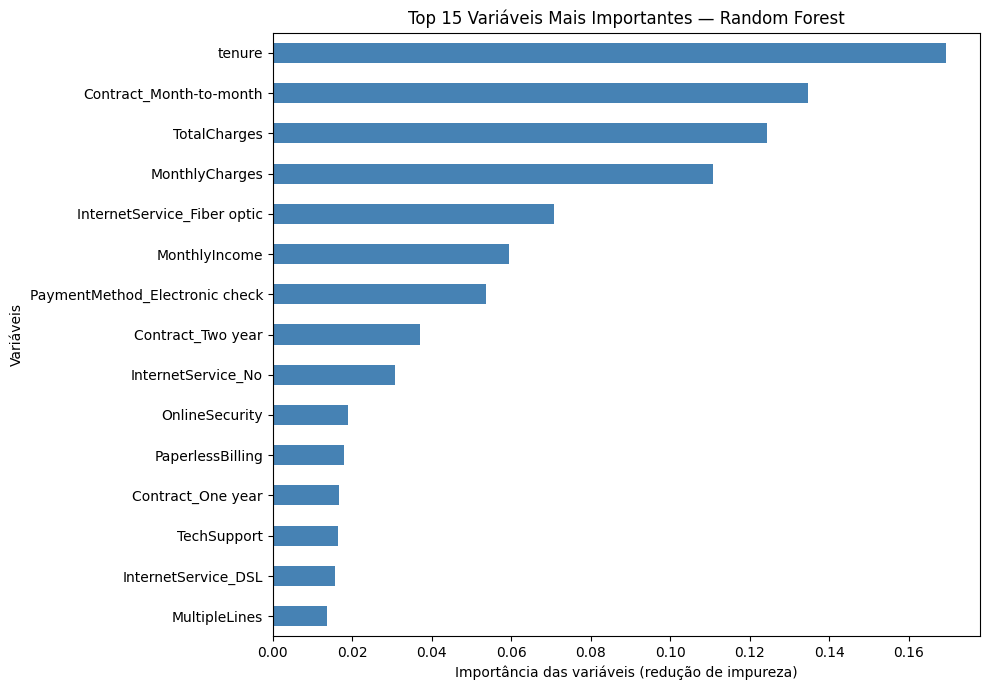

,Importancia
tenure,0.1695
Contract_Month-to-month,0.1347
TotalCharges,0.1243
MonthlyCharges,0.1108
InternetService_Fiber optic,0.0706
MonthlyIncome,0.0594
PaymentMethod_Electronic check,0.0537
Contract_Two year,0.0371
InternetService_No,0.0307
OnlineSecurity,0.0190


In [45]:
# 1. Extrai a importância das variáveis calculada pelo Random Forest
importancias_rf = pd.Series(
    modelo_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# 2. Seleciona as 15 variáveis com maior importância
top_15_rf = importancias_rf.head(15).sort_values()

# 3. Cria o gráfico
plt.figure(figsize=(10, 7))

top_15_rf.plot(
    kind='barh',
    color='steelblue'
)

plt.title('Top 15 Variáveis Mais Importantes — Random Forest')
plt.xlabel('Importância das variáveis (redução de impureza)')
plt.ylabel('Variáveis')
plt.tight_layout()
plt.show()

# 4. Exibe os valores em tabela
display(
    importancias_rf.head(15).to_frame(
        name='Importancia'
    ).round(4)
)

XGBoost

VALIDAÇÃO CRUZADA — XGBOOST


,Métrica,Média CV,Desvio CV
0,ROC-AUC,0.8353,0.0128
1,Average Precision,0.6316,0.0270
2,Accuracy,0.7890,0.0160
3,Precision,0.6277,0.0345
4,Recall,0.5138,0.0676
5,F1-score,0.5628,0.0465
6,Log Loss,0.4327,0.0150
7,Brier Score,0.1411,0.0066



TESTE — XGBOOST


,Modelo,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
0,XGBoost,0.8296,0.6345,0.7952,0.6255,0.5753,0.5993,0.442,0.1421


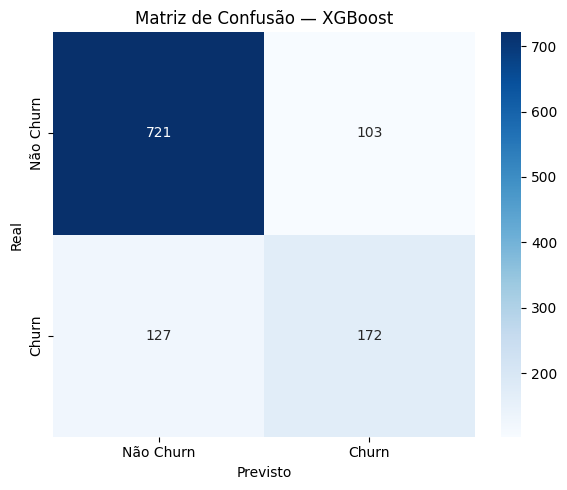

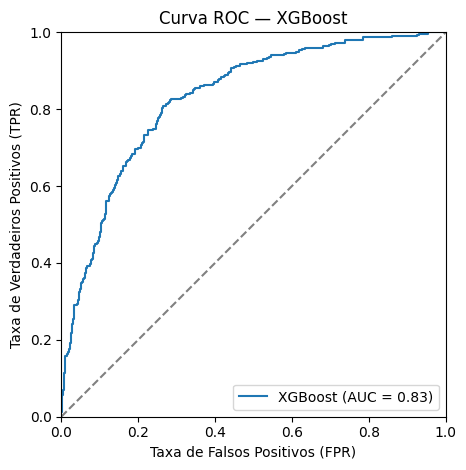

In [46]:
# 1. Cria o modelo XGBoost
modelo_xgb = XGBClassifier(
    n_estimators=300,           # Número de árvores
    max_depth=4,                # Profundidade máxima de cada árvore
    learning_rate=0.05,         # Taxa de contribuição de cada árvore
    subsample=0.8,              # Utiliza 80% das amostras por árvore
    colsample_bytree=0.8,       # Utiliza 80% das variáveis por árvore
    objective='binary:logistic',# Classificação binária com probabilidades
    eval_metric='logloss',      # Métrica interna de avaliação
    reg_lambda=1.0,             # Regularização L2
    tree_method='hist',         # Método eficiente de construção das árvores
    random_state=42,
    n_jobs=1                    # Evita paralelismo aninhado na validação
)

# 2. Executa validação cruzada nos mesmos folds
cv_results_xgb = cross_validate(
    modelo_xgb,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# 3. Organiza as métricas da validação cruzada
metricas_cv_xgb = pd.DataFrame({
    'Métrica': [
        'ROC-AUC', 'Average Precision', 'Accuracy',
        'Precision', 'Recall', 'F1-score',
        'Log Loss', 'Brier Score'
    ],
    'Média CV': [
        cv_results_xgb['test_roc_auc'].mean(),
        cv_results_xgb['test_average_precision'].mean(),
        cv_results_xgb['test_accuracy'].mean(),
        cv_results_xgb['test_precision'].mean(),
        cv_results_xgb['test_recall'].mean(),
        cv_results_xgb['test_f1'].mean(),
        -cv_results_xgb['test_neg_log_loss'].mean(),
        -cv_results_xgb['test_neg_brier_score'].mean()
    ],
    'Desvio CV': [
        cv_results_xgb['test_roc_auc'].std(),
        cv_results_xgb['test_average_precision'].std(),
        cv_results_xgb['test_accuracy'].std(),
        cv_results_xgb['test_precision'].std(),
        cv_results_xgb['test_recall'].std(),
        cv_results_xgb['test_f1'].std(),
        cv_results_xgb['test_neg_log_loss'].std(),
        cv_results_xgb['test_neg_brier_score'].std()
    ]
})

print("VALIDAÇÃO CRUZADA — XGBOOST")
display(metricas_cv_xgb.round(4))

# 4. Treina o XGBoost com todo o conjunto de treinamento
modelo_xgb.fit(X_train, y_train)

# 5. Gera previsões e probabilidades no conjunto de teste
y_pred_xgb = modelo_xgb.predict(X_test)
y_proba_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

# 6. Calcula as métricas no conjunto de teste
metricas_teste_xgb = {
    'Modelo': 'XGBoost',
    'ROC-AUC': roc_auc_score(y_test, y_proba_xgb),
    'Average Precision': average_precision_score(y_test, y_proba_xgb),
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb, zero_division=0),
    'Recall': recall_score(y_test, y_pred_xgb, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_xgb, zero_division=0),
    'Log Loss': log_loss(y_test, y_proba_xgb),
    'Brier Score': brier_score_loss(y_test, y_proba_xgb)
}

# 7. Armazena os resultados para comparação posterior
resultados_xgb = pd.DataFrame([metricas_teste_xgb])

print("\nTESTE — XGBOOST")
display(resultados_xgb.round(4))

# 8. Cria a matriz de confusão
matriz_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_xgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Não Churn', 'Churn'],
    yticklabels=['Não Churn', 'Churn']
)

plt.title('Matriz de Confusão — XGBoost')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

# 9. Exibe a curva ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_xgb,
    name='XGBoost'
)

plt.plot(
    [0, 1], [0, 1],
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.title('Curva ROC — XGBoost')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

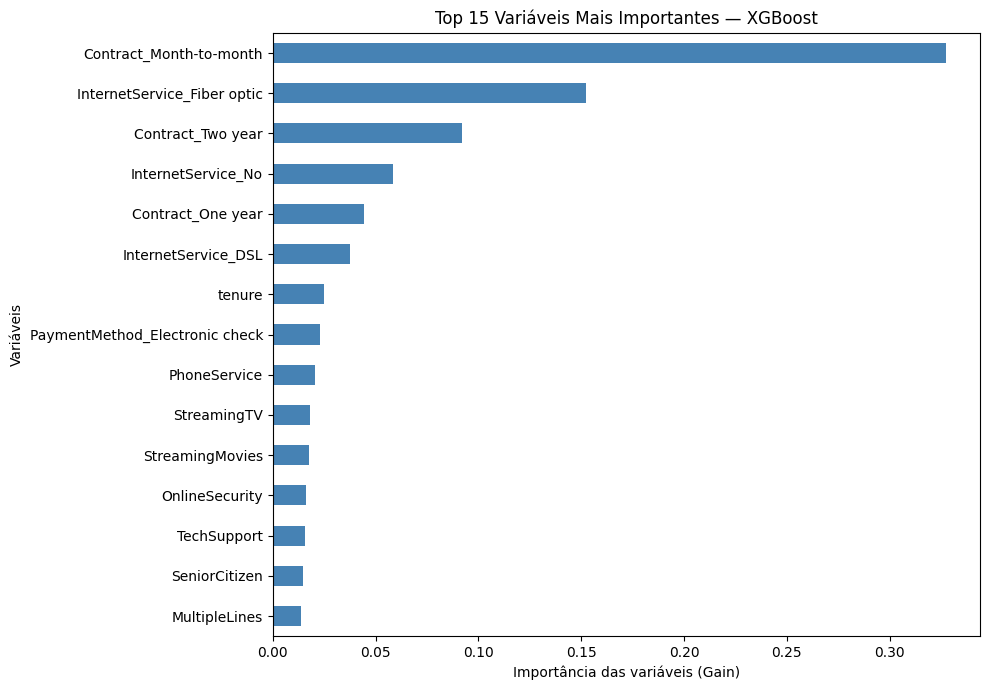

,Importancia
Contract_Month-to-month,0.3275
InternetService_Fiber optic,0.1521
Contract_Two year,0.0919
InternetService_No,0.0583
Contract_One year,0.0444
InternetService_DSL,0.0377
tenure,0.0250
PaymentMethod_Electronic check,0.0231
PhoneService,0.0205
StreamingTV,0.0180


In [47]:
# 1. Extrai as importâncias das variáveis do XGBoost
importancias_xgb = pd.Series(
    modelo_xgb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# 2. Seleciona as 15 variáveis mais importantes
top_15_xgb = importancias_xgb.head(15).sort_values()

# 3. Cria o gráfico
plt.figure(figsize=(10, 7))

top_15_xgb.plot(
    kind='barh',
    color='steelblue'
)

plt.title('Top 15 Variáveis Mais Importantes — XGBoost')
plt.xlabel('Importância das variáveis (Gain)')
plt.ylabel('Variáveis')
plt.tight_layout()
plt.show()

# 4. Exibe os valores em tabela
display(
    importancias_xgb.head(15).to_frame(
        name='Importancia'
    ).round(4)
)


LightGBM

VALIDAÇÃO CRUZADA — LIGHTGBM


,Métrica,Média CV,Desvio CV
0,ROC-AUC,0.8346,0.0127
1,Average Precision,0.6321,0.0264
2,Accuracy,0.7890,0.0113
3,Precision,0.6292,0.0304
4,Recall,0.5122,0.0626
5,F1-score,0.5621,0.0388
6,Log Loss,0.4344,0.0164
7,Brier Score,0.1417,0.0066



TESTE — LIGHTGBM


,Modelo,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
0,LightGBM,0.825,0.6249,0.7845,0.6075,0.5385,0.5709,0.4497,0.1448


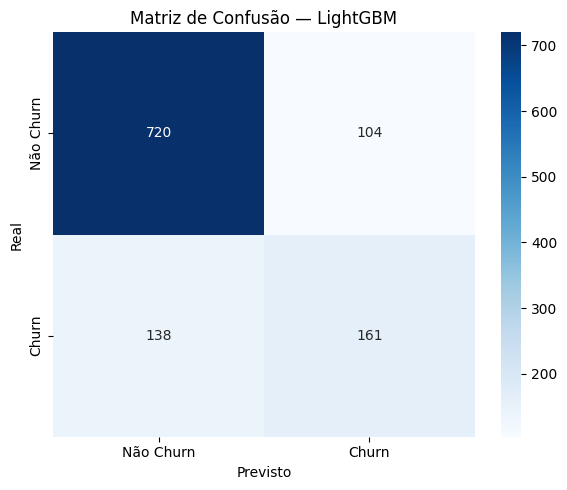

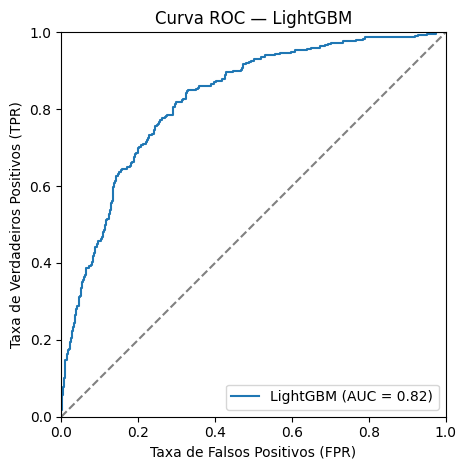

In [48]:
# 1. Cria o modelo LightGBM
modelo_lgbm = LGBMClassifier(
    n_estimators=300,           # Número de árvores
    num_leaves=15,              # Número máximo de folhas por árvore
    max_depth=5,                # Profundidade máxima de cada árvore
    learning_rate=0.05,         # Taxa de contribuição de cada árvore
    min_child_samples=20,       # Mínimo aproximado de clientes por folha
    subsample=0.8,              # Utiliza 80% das amostras
    subsample_freq=1,           # Ativa o subsampling a cada iteração
    colsample_bytree=0.8,       # Utiliza 80% das variáveis por árvore
    reg_lambda=1.0,             # Regularização L2
    objective='binary',         # Classificação binária
    importance_type='gain',     # Importância baseada na redução da perda
    random_state=42,
    n_jobs=1,                   # Evita paralelismo aninhado na validação
    verbosity=-1                # Oculta mensagens informativas do LightGBM
)

# 2. Executa validação cruzada nos mesmos folds
cv_results_lgbm = cross_validate(
    modelo_lgbm,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# 3. Organiza as métricas da validação cruzada
metricas_cv_lgbm = pd.DataFrame({
    'Métrica': [
        'ROC-AUC', 'Average Precision', 'Accuracy',
        'Precision', 'Recall', 'F1-score',
        'Log Loss', 'Brier Score'
    ],
    'Média CV': [
        cv_results_lgbm['test_roc_auc'].mean(),
        cv_results_lgbm['test_average_precision'].mean(),
        cv_results_lgbm['test_accuracy'].mean(),
        cv_results_lgbm['test_precision'].mean(),
        cv_results_lgbm['test_recall'].mean(),
        cv_results_lgbm['test_f1'].mean(),
        -cv_results_lgbm['test_neg_log_loss'].mean(),
        -cv_results_lgbm['test_neg_brier_score'].mean()
    ],
    'Desvio CV': [
        cv_results_lgbm['test_roc_auc'].std(),
        cv_results_lgbm['test_average_precision'].std(),
        cv_results_lgbm['test_accuracy'].std(),
        cv_results_lgbm['test_precision'].std(),
        cv_results_lgbm['test_recall'].std(),
        cv_results_lgbm['test_f1'].std(),
        cv_results_lgbm['test_neg_log_loss'].std(),
        cv_results_lgbm['test_neg_brier_score'].std()
    ]
})

print("VALIDAÇÃO CRUZADA — LIGHTGBM")
display(metricas_cv_lgbm.round(4))

# 4. Treina o LightGBM com todo o conjunto de treinamento
modelo_lgbm.fit(X_train, y_train)

# 5. Gera previsões e probabilidades no conjunto de teste
y_pred_lgbm = modelo_lgbm.predict(X_test)
y_proba_lgbm = modelo_lgbm.predict_proba(X_test)[:, 1]

# 6. Calcula as métricas no conjunto de teste
metricas_teste_lgbm = {
    'Modelo': 'LightGBM',
    'ROC-AUC': roc_auc_score(y_test, y_proba_lgbm),
    'Average Precision': average_precision_score(y_test, y_proba_lgbm),
    'Accuracy': accuracy_score(y_test, y_pred_lgbm),
    'Precision': precision_score(y_test, y_pred_lgbm, zero_division=0),
    'Recall': recall_score(y_test, y_pred_lgbm, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_lgbm, zero_division=0),
    'Log Loss': log_loss(y_test, y_proba_lgbm),
    'Brier Score': brier_score_loss(y_test, y_proba_lgbm)
}

# 7. Armazena os resultados para comparação posterior
resultados_lgbm = pd.DataFrame([metricas_teste_lgbm])

print("\nTESTE — LIGHTGBM")
display(resultados_lgbm.round(4))

# 8. Cria a matriz de confusão
matriz_lgbm = confusion_matrix(y_test, y_pred_lgbm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_lgbm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Não Churn', 'Churn'],
    yticklabels=['Não Churn', 'Churn']
)

plt.title('Matriz de Confusão — LightGBM')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

# 9. Exibe a curva ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_lgbm,
    name='LightGBM'
)

plt.plot(
    [0, 1], [0, 1],
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.title('Curva ROC — LightGBM')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

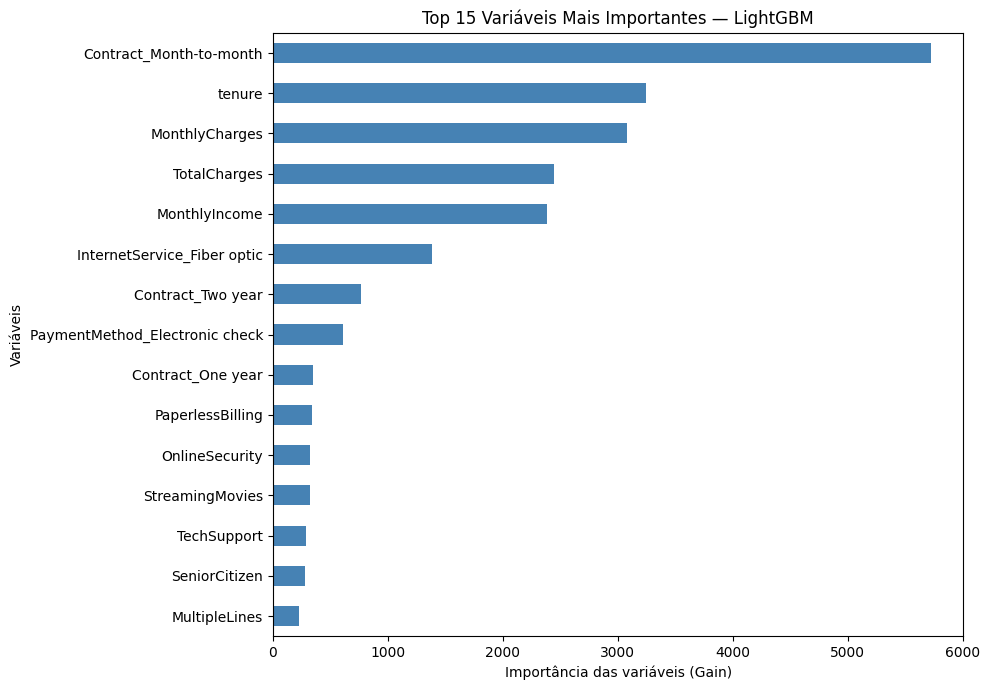

,Importancia
Contract_Month-to-month,5721.4972
tenure,3244.8698
MonthlyCharges,3083.3503
TotalCharges,2443.2718
MonthlyIncome,2384.0001
InternetService_Fiber optic,1382.1331
Contract_Two year,764.6845
PaymentMethod_Electronic check,608.1195
Contract_One year,346.7205
PaperlessBilling,344.0136


In [49]:
# 1. Extrai a importância das variáveis
importancias_lgbm = pd.Series(
    modelo_lgbm.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# 2. Seleciona as 15 variáveis mais importantes
top_15_lgbm = importancias_lgbm.head(15).sort_values()

# 3. Cria o gráfico 
plt.figure(figsize=(10, 7))

top_15_lgbm.plot(
    kind='barh',
    color='steelblue'
)

plt.title('Top 15 Variáveis Mais Importantes — LightGBM')
plt.xlabel('Importância das variáveis (Gain)')
plt.ylabel('Variáveis')
plt.tight_layout()
plt.show()

# 4. Exibe os valores em tabela
display(
    importancias_lgbm.head(15).to_frame(
        name='Importancia'
    ).round(4)
)

Comparações

In [50]:
# 1. Reúne os resultados da validação cruzada dos 7 modelos
modelos_cv = {
    'Logistic Regression': metricas_cv,
    'KNN': metricas_cv_knn,
    'MLP': metricas_cv_mlp,
    'Decision Tree': metricas_cv_dt,
    'Random Forest': metricas_cv_rf,
    'XGBoost': metricas_cv_xgb,
    'LightGBM': metricas_cv_lgbm
}

# 2. Consolida as médias e os desvios de cada métrica
comparacao_cv = pd.concat({
    nome: tabela.set_index('Métrica')
    for nome, tabela in modelos_cv.items()
}, names=['Modelo', 'Métrica']).reset_index()

# 3. Cria a tabela comparativa com as médias
comparacao_modelos = comparacao_cv.pivot(
    index='Modelo',
    columns='Métrica',
    values='Média CV'
)

# 4. Organiza as colunas na ordem desejada
ordem_metricas = [
    'ROC-AUC', 'Average Precision', 'Accuracy',
    'Precision', 'Recall', 'F1-score',
    'Log Loss', 'Brier Score'
]

comparacao_modelos = comparacao_modelos[ordem_metricas]

# 5. Ordena os modelos pelo maior ROC-AUC
comparacao_modelos = comparacao_modelos.sort_values(
    by='ROC-AUC',
    ascending=False
)

# 6. Exibe a tabela comparativa
print("COMPARATIVO DOS MODELOS — MÉDIA DA VALIDAÇÃO CRUZADA")
display(comparacao_modelos.round(4))

COMPARATIVO DOS MODELOS — MÉDIA DA VALIDAÇÃO CRUZADA


Métrica,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
Modelo,,,,,,,,
Random Forest,0.8397,0.6427,0.7985,0.6609,0.4988,0.5667,0.4255,0.1382
Logistic Regression,0.8369,0.6446,0.7974,0.6443,0.5331,0.5819,0.4282,0.1392
XGBoost,0.8353,0.6316,0.7890,0.6277,0.5138,0.5628,0.4327,0.1411
LightGBM,0.8346,0.6321,0.7890,0.6292,0.5122,0.5621,0.4344,0.1417
MLP,0.8331,0.6323,0.7916,0.6359,0.5122,0.5649,0.4326,0.1411
Decision Tree,0.8213,0.5925,0.7883,0.6147,0.5580,0.5838,0.5093,0.1455
KNN,0.7797,0.5165,0.7663,0.5681,0.5138,0.5392,1.6467,0.1643


In [51]:
# 1. Cria a tabela com os desvios-padrão
comparacao_desvio = comparacao_cv.pivot(
    index='Modelo',
    columns='Métrica',
    values='Desvio CV'
)

# 2. Mantém a mesma ordem dos modelos e das métricas
comparacao_desvio = comparacao_desvio.loc[
    comparacao_modelos.index,
    ordem_metricas
]

# 3. Exibe os resultados
print("COMPARATIVO DOS MODELOS — DESVIO-PADRÃO DA VALIDAÇÃO CRUZADA")
display(comparacao_desvio.round(4))

COMPARATIVO DOS MODELOS — DESVIO-PADRÃO DA VALIDAÇÃO CRUZADA


Métrica,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
Modelo,,,,,,,,
Random Forest,0.0138,0.0281,0.0122,0.0173,0.0635,0.0458,0.0134,0.0055
Logistic Regression,0.0152,0.0324,0.0155,0.0272,0.0654,0.0461,0.0153,0.0056
XGBoost,0.0128,0.0270,0.0160,0.0345,0.0676,0.0465,0.0150,0.0066
LightGBM,0.0127,0.0264,0.0113,0.0304,0.0626,0.0388,0.0164,0.0066
MLP,0.0129,0.0282,0.0119,0.0261,0.0681,0.0431,0.0143,0.0056
Decision Tree,0.0126,0.0188,0.0144,0.0335,0.0408,0.0278,0.0564,0.0054
KNN,0.0170,0.0280,0.0114,0.0227,0.0329,0.0253,0.2312,0.0085


In [ ]:
# Comparação dos modelos no conjunto de teste
# 1. Reúne os resultados de teste dos 7 modelos
comparacao_teste = pd.concat([
    resultados_modelos,  # Logistic Regression
    resultados_knn,
    resultados_mlp,
    resultados_dt,
    resultados_rf,
    resultados_xgb,
    resultados_lgbm
], ignore_index=True)

# 2. Define o nome do modelo como índice
comparacao_teste = comparacao_teste.set_index('Modelo')

# 3. Organiza as métricas
comparacao_teste = comparacao_teste[ordem_metricas]

# 4. Ordena os modelos pelo maior ROC-AUC
comparacao_teste = comparacao_teste.sort_values(
    by='ROC-AUC',
    ascending=False
)

# 5. Exibe a tabela
print("COMPARATIVO DOS MODELOS — CONJUNTO DE TESTE")
display(comparacao_teste.round(4))

COMPARATIVO DOS MODELOS — CONJUNTO DE TESTE


,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score,Log Loss,Brier Score
Modelo,,,,,,,,
Logistic Regression,0.8525,0.6754,0.8210,0.6885,0.5987,0.6404,0.4100,0.1323
Random Forest,0.8442,0.6617,0.8059,0.6695,0.5351,0.5948,0.4186,0.1357
MLP,0.8434,0.6421,0.8094,0.6592,0.5886,0.6219,0.4195,0.1362
XGBoost,0.8296,0.6345,0.7952,0.6255,0.5753,0.5993,0.4420,0.1421
LightGBM,0.8250,0.6249,0.7845,0.6075,0.5385,0.5709,0.4497,0.1448
Decision Tree,0.8242,0.6154,0.7943,0.6197,0.5886,0.6038,0.5814,0.1428
KNN,0.7834,0.5177,0.7631,0.5567,0.5418,0.5492,1.4717,0.1624


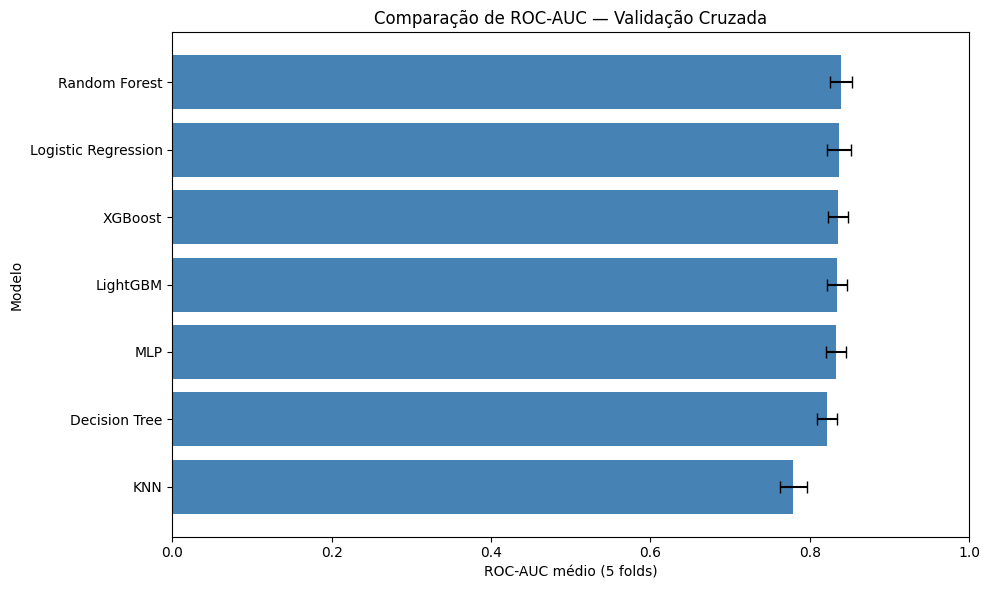

In [53]:
# 1. Recupera as médias e os desvios de ROC-AUC
roc_auc_media = comparacao_modelos['ROC-AUC']
roc_auc_desvio = comparacao_desvio['ROC-AUC']

# 2. Cria o gráfico
plt.figure(figsize=(10, 6))

plt.barh(
    roc_auc_media.index,
    roc_auc_media.values,
    xerr=roc_auc_desvio.values,
    color='steelblue',
    capsize=4
)

plt.title('Comparação de ROC-AUC — Validação Cruzada')
plt.xlabel('ROC-AUC médio (5 folds)')
plt.ylabel('Modelo')
plt.xlim(0, 1)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()